# Phase 3: Explainable AI & Network Deficit Score
**Objective:** Identify the main drivers of predicted capacity stress with SHAP, and combine the forecasts into a Network Deficit Score (NDS) that ranks sub-counties for infrastructure-upgrade assessment.

| | |
|---|---|
| **Pipeline** | 01 Spatial canvas → 02 Temporal extraction → 03 Spatial downscale → 04 MTL engine → **05 Explainability & NDS** |
| **Answers** | Research Question 4 and Specific Objective 3; hypothesis H4, plus the summary of H1–H4 |
| **Inputs** | `Outputs/models/` from Notebook 04 (final GRU-MTL seeds, XGBoost pair, scalers, Q4 2025/26 forecast); `Data/processed/sites_all_technologies.csv` from Notebook 01; `Data/processed/site_catchment_demand.parquet` and `subcounty_panel.parquet` from Notebook 03; Tables 4.18 and 4.19 |
| **Outputs** | Tables 4.23–4.32 (including the priority list, watch list, candidate sites and full ranking); Figures 4.9–4.15 |

**What this notebook does, in plain words.** Notebook 04 produced, for every sub-county, a forecast for the next quarter (Q4 2025/26): the probability that the sub-county will be *stressed* (in the top 20% of load relative to capacity) and the size of its capacity gap if it is. This notebook answers two follow-up questions:
1. **Why** do the models forecast stress where they do? This is the *explainable AI* part (Steps 2 and 5).
2. **Where** should an operator or regulator look first? This is the *Network Deficit Score* part, which combines the forecasts into one score and a ranked list (Steps 3 to 8).

**Key terms used throughout**
- **Explainable AI (XAI):** methods that show how a "black-box" model, such as a neural network or a large set of decision trees, arrives at its predictions, so that people can check them and decide whether to trust them.
- **Shapley value:** an idea from cooperative game theory. When several players share a payout, a player's Shapley value is its average extra contribution over every possible order in which the players could join the team. Here the "players" are the input features and the "payout" is the model's prediction for one sub-county.
- **SHAP (SHapley Additive exPlanations):** the method of Lundberg & Lee (2017) that computes Shapley values for model predictions. For each sub-county, *prediction = base value + the sum of the SHAP values of all features*, where the base value is the model's average prediction. A **positive** SHAP value means the feature pushed that sub-county's forecast **towards** stress; a **negative** value means it pushed the forecast away from stress. The size of the value shows how strongly.
- **Global and local explanations:** a global explanation summarises which features matter across all sub-counties (Step 2); a local explanation shows why one particular sub-county received its forecast (Step 5).

**Structure:**
1. Global explanations: TreeSHAP for XGBoost and GradientSHAP for GRU-MTL, grouped into feature families, with **target-formula components separated from independent predictors** (proposal Section 3.4.5)
2. Explanation stability: rank agreement across the 5 GRU-MTL seeds, between the two model families, and across temporal training windows
3. NDS construction: three non-redundant components, each normalised
4. Robustness (hypothesis **H4**): random weight perturbations, alternative weighting schemes, seed-to-seed model uncertainty and a model swap, with county-level movement; spatial clustering of the NDS
5. Local explanations for the highest-priority sub-counties
6. Maps, a county summary and the ranked screening table (priority list and watch list)
7. Candidate sites inside the top-priority sub-counties
8. Summary of the four hypotheses and the full ranking

SHAP values are **model attributions, not causal effects** (Lundberg & Lee, 2017). Correlated features share attribution, which is why results are also reported by feature family. Put simply, SHAP tells us what the model relied on, not what physically causes congestion; and when two features carry similar information, the credit can be split between them somewhat arbitrarily, so adding the credit up by family gives a steadier picture.

### Setup: load what Notebook 04 saved
The first code cell does no new modelling. It loads the files Notebook 04 wrote to `Outputs/models/`:
- `config.json` → `cfg`: the feature lists and settings Notebook 04 used. `ALL_DYN` are the *dynamic* features (they change from quarter to quarter), `STAT` are the *static* features (fixed per sub-county), `TAB` is the flat feature list given to XGBoost, `L` is the 4-quarter look-back window and `SEEDS` are the 5 random seeds of GRU-MTL.
- `arrays_next.npz` → `arr`: the numeric arrays. `seq_next` holds the last 4 quarters of every sub-county (the input for the forecast), `Xs_unit` the static features per sub-county and `units` the sub-county names. It also holds the historical windows the models were trained on (`seq`, `stat`, the target quarter `tq` and the stress label `y_c`) and the nearest-neighbour list `nn_idx`.
- `forecast_next_quarter.parquet` → `forecast`: one row per sub-county with the forecast stress probability (`breach_prob`), the predicted gap if stressed (`pred_gap_TB`), the XGBoost probability, the Ookla devices and the data-quality flags.

It then defines three dictionaries that are used later:
- `FAMILY` groups the individual features into **feature families** (for example, the current stress ratio and its three lags form one family).
- `TARGET_COMPONENT` lists the features that are **part of the formula for the target itself**. The proposal (Section 3.4.5) requires these to be kept apart from independent predictors, because a feature that is part of the target formula will naturally look important without explaining anything new.
- `LABEL` gives short readable names for the tables.

**The features in plain words** (code name → meaning):

| Feature | Meaning | Role |
|---|---|---|
| `rel_ratio` | current stress ratio (load/capacity relative to the quarter's stress threshold, log scale) | target-formula component |
| `rel_ratio_lag1` to `rel_ratio_lag3` | the same ratio one, two and three quarters earlier (separate columns for XGBoost only) | target-formula component |
| `log_gap` | current load gap (log scale) | target-formula component |
| `dev_share_pct` | the sub-county's share of Ookla devices (%) | target-formula component |
| `log_capacity`, `lte_share`, `umts_share` | capacity proxy from recorded cells (log scale), and the share of cells that are LTE or UMTS | target-formula component |
| `log_tests`, `low_confidence` | number of Ookla tests (log scale), and a flag for few tests | independent predictor |
| `dl_mbps_f` | Ookla download speed | independent predictor |
| `splag_rel_ratio`, `splag_dev_share_pct` | average stress ratio and device share of the 5 nearest sub-counties | independent predictor |
| `log_sites` | number of recorded OpenCellID sites (log scale) | independent predictor |
| `nat_growth` | national growth, the same for every sub-county in a quarter | independent predictor |

In [1]:
# project_config holds the shared paths, constants and helpers (save_table, save_figure,
# minmax, morans_i, SeqNet, StressProb). '*' imports every name, including np, pd and plt.
from project_config import *
import warnings
warnings.filterwarnings('ignore')        # set before importing shap, which otherwise warns on import
import json, pickle      # json reads the settings file; pickle reads the saved scaler objects
import torch             # PyTorch, needed to rebuild the GRU-MTL networks
import shap              # the SHAP explainability library
import xgboost as xgb
from scipy.stats import spearmanr      # Spearman rank correlation, for every rank comparison

# Load Notebook 04's outputs. json.load turns the JSON file into a Python dictionary (cfg).
cfg = json.load(open(MODELS + 'config.json'))
# np.load on a .npz file gives a dictionary-like archive of named numpy arrays.
# allow_pickle=True is needed because the sub-county names are stored as Python objects.
arr = np.load(MODELS + 'arrays_next.npz', allow_pickle=True)
forecast = pd.read_parquet(MODELS + 'forecast_next_quarter.parquet')   # one row per sub-county
ALL_DYN, STAT, TAB, L, SEEDS = cfg['ALL_DYN'], cfg['STAT'], cfg['TAB'], cfg['L'], cfg['SEEDS']   # as fitted in Notebook 04
# seq_next has shape (sub-counties, 4 quarters, dynamic features): the forecast input.
# Xs_unit has shape (sub-counties, static features). units: sub-county names in the same order.
seq_next, Xs_unit, units = arr['seq_next'], arr['Xs_unit'], arr['units']
N = len(units)      # number of sub-counties
# An f-string (f"...") evaluates the expressions inside {} and inserts them into the text.
print(f"Forecast quarter: {forecast['forecast_quarter'].iloc[0]} | sub-counties: {N}")

# Feature families. Each family is either part of the stress-ratio formula r = Y·W(devices) / C(n_GSM, n_UMTS, n_LTE)
# (a "target-formula component") or an independent predictor, so the two are never mixed in one family.
# Dictionary: feature name -> family name.
FAMILY = {
    'rel_ratio': 'Current and lagged stress ratio and gap', 'log_gap': 'Current and lagged stress ratio and gap',
    'rel_ratio_lag1': 'Current and lagged stress ratio and gap', 'rel_ratio_lag2': 'Current and lagged stress ratio and gap',
    'rel_ratio_lag3': 'Current and lagged stress ratio and gap',
    'dev_share_pct': 'Demand share (Ookla devices)',
    'log_capacity': 'Capacity proxy and technology mix', 'lte_share': 'Capacity proxy and technology mix',
    'umts_share': 'Capacity proxy and technology mix',
    'log_tests': 'Ookla test volume and confidence', 'low_confidence': 'Ookla test volume and confidence',
    'dl_mbps_f': 'Observed quality (Ookla speed)',
    'splag_rel_ratio': 'Spatial neighbourhood', 'splag_dev_share_pct': 'Spatial neighbourhood',
    'log_sites': 'Recorded sites',
    'nat_growth': 'National trend',
}
# A set (curly brackets, no values) of the features that are part of the target formula.
TARGET_COMPONENT = {'rel_ratio', 'log_gap', 'rel_ratio_lag1', 'rel_ratio_lag2', 'rel_ratio_lag3',
                    'dev_share_pct', 'log_capacity', 'lte_share', 'umts_share'}
# Readable labels used in the screening table (Step 7).
LABEL = {'rel_ratio': 'current stress ratio', 'log_gap': 'current gap', 'dev_share_pct': 'device share',
         'log_tests': 'Ookla tests', 'dl_mbps_f': 'download speed', 'low_confidence': 'few-tests flag',
         'nat_growth': 'national growth', 'splag_rel_ratio': "neighbours' stress ratio",
         'splag_dev_share_pct': "neighbours' device share", 'log_capacity': 'capacity proxy',
         'lte_share': 'LTE share', 'umts_share': 'UMTS share', 'log_sites': 'recorded sites'}

Forecast quarter: Q4_25_26 | sub-counties: 294


## Step 1: Rebuild the Models
`SeqNet` (the GRU-MTL network) and the `StressProb` wrapper come from `project_config.py`, the same definitions Notebook 04 trained with.

**What happens here.** Notebook 04 saved only the *learned numbers* (the weights) of each network, not a ready-to-run model. To use a network again, the code first builds an empty network with exactly the same architecture and then loads the saved weights into it. This is done for each of the 5 GRU-MTL seeds, so the explanations later cover all five trained versions of the model rather than one possibly lucky run.

- `scalers` is a list of 5 dictionaries, one per seed. Each holds the standardisation objects for the dynamic (`'dyn'`) and static (`'stat'`) inputs, the mean and standard deviation used to standardise the log gap (`'gmu'`, `'gsd'`), and the positions of the dynamic columns that the model uses (`'dyn_cols'`). New inputs must be scaled in exactly the same way as the training data, otherwise the network would receive numbers on a scale it has never seen.
- The XGBoost stress classifier is the benchmark model; it is reloaded from its saved JSON file.
- `to_tab` converts the 3-D sequence array (sub-counties × quarters × features) into the flat table XGBoost expects: the features of the most recent quarter, the stress ratio one, two and three quarters earlier (`rel_ratio_lag1` to `rel_ratio_lag3`), and the static covariates. `tab_next` is this table for the forecast quarter.

In [2]:
# Load the 5 sets of input scalers (one dictionary per seed). 'rb' opens the file in binary
# read mode, which pickle needs.
scalers = pickle.load(open(MODELS + 'gru_mtl_final_scalers.pkl', 'rb'))
gru_models = []
# zip pairs each seed number with its own scalers: (0, scalers[0]), (1, scalers[1]), ...
for s, sc in zip(SEEDS, scalers):
    # Build an empty GRU-MTL network of the same shape as in Notebook 04: number of dynamic
    # inputs, number of static inputs, hidden size, GRU cell, and 'mtl' = both output heads.
    m = SeqNet(len(sc['dyn_cols']), len(STAT), cfg['HIDDEN'], 'gru', 'mtl')
    # torch.load reads the saved weights (a dictionary of tensors); map_location='cpu' loads
    # them on the CPU. load_state_dict copies them into the empty network.
    m.load_state_dict(torch.load(MODELS + f'gru_mtl_final_seed{s}.pth', map_location='cpu'))
    m.eval(); gru_models.append(m)    # eval() switches off dropout, so outputs are repeatable

# Create an empty XGBoost classifier object, then load the trees saved by Notebook 04.
xgb_clf = xgb.XGBClassifier(); xgb_clf.load_model(MODELS + 'xgb_clf_final.json')

def to_tab(seq_arr, stat_arr):
    """Tabular features exactly as in Notebook 04: last quarter of the window, three lags of the ratio, static covariates."""
    # seq_arr[:, -1, :] = every sub-county (:), the last quarter (-1), all features (:).
    t = pd.DataFrame(seq_arr[:, -1, :], columns=ALL_DYN)
    for k in [1, 2, 3]:
        # Feature 0 is the stress ratio; quarter position -1 - k is k quarters before the last.
        t[f'rel_ratio_lag{k}'] = seq_arr[:, -1 - k, 0]
    # enumerate gives (position, name) pairs, so column j of stat_arr becomes feature c.
    for j, c in enumerate(STAT):
        t[c] = stat_arr[:, j]
    return t[TAB]        # the same columns, in the same order, as XGBoost was trained on

tab_next = to_tab(seq_next, Xs_unit)    # XGBoost input for the forecast quarter, one row each
print("Models loaded:", len(gru_models), "GRU-MTL seeds + XGBoost")

Models loaded: 5 GRU-MTL seeds + XGBoost


## Step 2: Global Explanations
A **global explanation** answers the question "which inputs does the model rely on most, across all sub-counties?". Two different SHAP algorithms are needed because the two models are built differently: XGBoost is a collection of decision trees, while GRU-MTL is a neural network.

### 2.1 TreeSHAP for the XGBoost stress classifier (exact, all sub-counties)
**TreeSHAP** is a SHAP algorithm written specifically for tree models such as XGBoost. It follows the structure of every tree and computes the Shapley values **exactly** and quickly, instead of estimating them by random sampling. It is applied to all sub-counties in the forecast table `tab_next`.

**How the code works.**
- `shap.TreeExplainer(xgb_clf)` prepares the explainer for the loaded model, and calling it on `tab_next` returns an *Explanation* object, `sv_xgb`. Its `.values` is a table of SHAP values with one row per sub-county and one column per feature, and `.base_values` holds the model's average output (the starting point that the SHAP values are added to).
- The XGBoost classifier's raw output is in **log-odds**, $\log\big(p/(1-p)\big)$, where $p$ is the stress probability. A log-odds of 0 corresponds to $p = 0.5$, and each +1 multiplies the odds of stress by about 2.7. These SHAP values are therefore in log-odds, not in percentage points.
- `imp_xgb` is the **mean absolute SHAP value** (mean |SHAP|) of each feature: the average size of its contribution, ignoring whether it pushed up or down. This is the standard SHAP measure of global importance.

**How to read Figure 4.9 (beeswarm plot).**
- Each row is a feature, sorted from most important (top) to least important (bottom). At most 15 rows are drawn; the least important features are combined in the last row.
- Each dot is **one sub-county**. Its horizontal position is that feature's SHAP value for that sub-county: dots to the **right of 0** raised the predicted chance of stress, dots to the **left** lowered it.
- The colour shows the feature's own value: **red = high, blue = low**. As a reading guide (not a result): if a feature's red dots sit on the right and its blue dots on the left, high values of that feature push the forecast towards stress.
- A wide spread of dots means the feature matters a lot for some sub-counties; a tight cluster around 0 means it hardly matters.

[saved] Outputs/figures/F4.09_shap_xgb_beeswarm.png


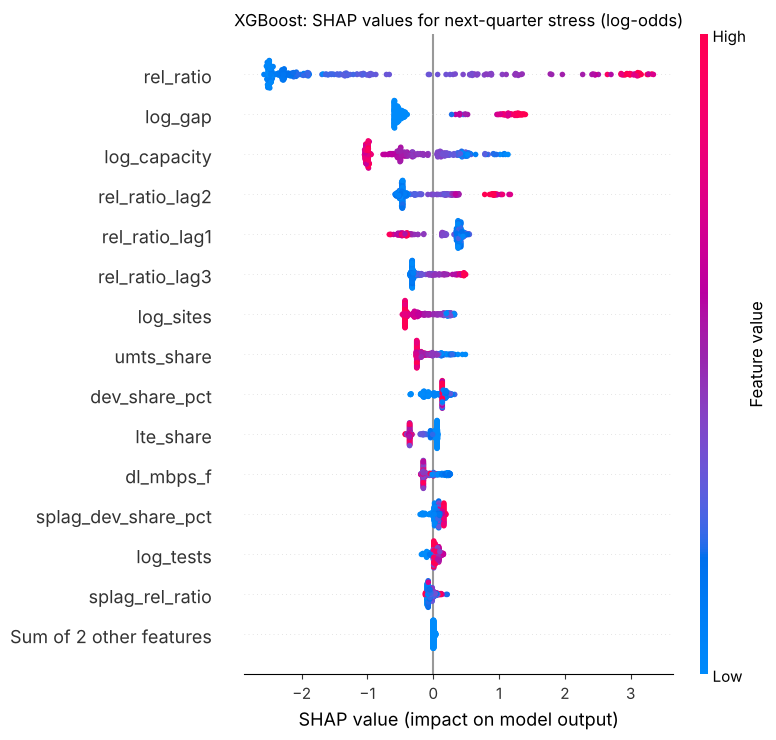

In [3]:
# Build the TreeSHAP explainer for the XGBoost classifier and compute SHAP values for every
# sub-county. sv_xgb.values has shape (sub-counties, features), in log-odds units.
tree_exp = shap.TreeExplainer(xgb_clf)
sv_xgb = tree_exp(tab_next)
plt.figure()       # start a fresh, empty figure for the plot
# Beeswarm plot (Figure 4.9). show=False keeps the figure open so a title can be added and
# the figure saved before it is displayed.
shap.plots.beeswarm(sv_xgb, max_display=15, show=False)
plt.title('XGBoost: SHAP values for next-quarter stress (log-odds)')
# tight_layout stops labels being cut off; save_figure writes Outputs/figures/F4.09_...png.
plt.tight_layout(); save_figure('4.09', 'shap_xgb_beeswarm'); plt.show()
# Global importance = mean |SHAP| down each column (axis 0 = across sub-counties).
# np.abs removes the sign, so pushes up and pushes down both count as importance.
imp_xgb = pd.Series(np.abs(sv_xgb.values).mean(0), index=TAB).astype(float)

### 2.2 GradientSHAP for GRU-MTL (expected gradients, each of the 5 seeds)
Background: 100 randomly drawn training windows. Attributions are summed over the 4 lookback quarters to give one value per feature, and static covariates are explained through the second input. The values are on the **probability** scale of the stress head.

**What GradientSHAP is.** TreeSHAP works only for trees, so the neural network needs a different method. **GradientSHAP** (also called *expected gradients*) uses the network's **gradients**, that is, how much the output changes when an input is nudged slightly. For one sub-county it repeats the following steps many times (here 200, `nsamples=200`):
1. pick a random reference window from the background sample;
2. pick a random point on the straight line between that reference and the sub-county's actual input;
3. multiply the gradient at that point by the difference between the actual input and the reference.

Averaging these products gives an approximate SHAP value for every input. Because it relies on random draws, GradientSHAP gives an **estimate**, not an exact value as TreeSHAP does; `rseed=0` fixes the random draws so that the result is the same every time the notebook runs.

**Background sample.** SHAP values always explain a prediction *relative to a reference*. The **background sample** is the set of "typical" inputs that defines this reference: here 100 windows drawn at random (`bg_rows`) from the historical windows. A SHAP value then answers "how far did this feature move the forecast away from what the model predicts on typical historical data?". On the probability scale, a SHAP value of +0.10 (an illustrative number) means the feature raised that sub-county's stress probability by about 10 percentage points.

**How the code works.**
- `gru_shap(model, sc)` scales the inputs exactly as in training (`scale_d` for the dynamic sequence, `scale_s` for the static features), wraps the network in `StressProb` so that only the stress probability is explained (not the gap head), and runs `shap.GradientExplainer`.
- The network has **two inputs** (the 4-quarter sequence and the static features), so SHAP returns two arrays: one of shape (sub-counties, 4 quarters, dynamic features) and one of shape (sub-counties, static features). Summing the first over the 4 quarters gives one value per feature, and the two are joined into one table with one row per sub-county. Because the past quarters are inside the sequence, GRU-MTL has no separate lag features: the history of the stress ratio is included in `rel_ratio`.
- This is repeated for each of the 5 seeds (`gru_sv`). `imp_gru_seeds` holds the mean |SHAP| per feature and seed, `imp_gru` averages it over the seeds, and `sv_gru_mean` is the seed average of the signed SHAP values for each sub-county (used in the screening table in Step 7).

**How to read Figure 4.10.** Each bar is a feature's mean |SHAP| on the stress probability, averaged over the 5 seeds, so a longer bar means the feature moves the GRU-MTL forecast more. The thin error bars show ± one standard deviation across the seeds: short error bars mean that the five trained versions of the model agree on how important the feature is.

[saved] Outputs/figures/F4.10_shap_gru_importance.png


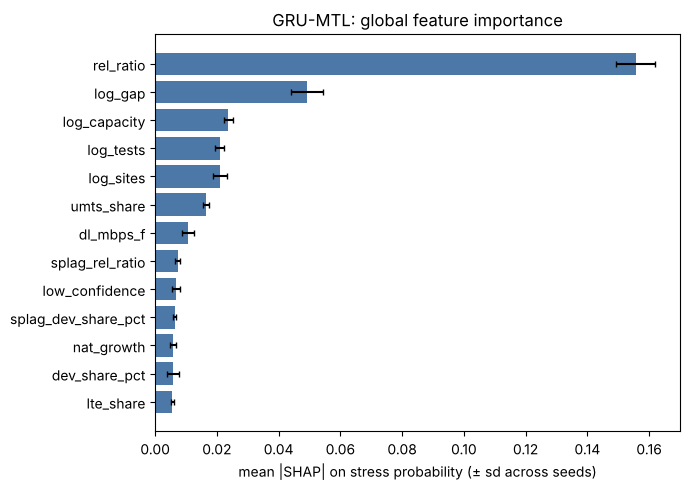

In [4]:
# Choose the background sample: 100 different window numbers drawn at random (without
# replacement) from all historical windows; arr['tq'] has one entry per window.
rng = np.random.default_rng(42)      # random number generator with a fixed seed
bg_rows = rng.choice(len(arr['tq']), 100, replace=False)

def gru_shap(model, sc):
    # cols: positions of the dynamic features this model uses; F: how many there are.
    cols = sc['dyn_cols']; F = len(cols)
    # scale_d scales a 3-D sequence array as in training. The scaler expects a 2-D table, so
    # reshape to (windows * quarters, F), transform, reshape back to (windows, L, F) and
    # convert to a float32 PyTorch tensor. 'lambda' defines a small one-line function.
    scale_d = lambda x: torch.tensor(sc['dyn'].transform(x[:, :, cols].reshape(-1, F)).reshape(len(x), L, F), dtype=torch.float32)
    # scale_s does the same for the static features, which are already a 2-D table.
    scale_s = lambda x: torch.tensor(sc['stat'].transform(x), dtype=torch.float32)
    # StressProb(model) outputs only the stress probability. The list gives the explainer the
    # background windows for both inputs (sequence and static features).
    exp = shap.GradientExplainer(StressProb(model), [scale_d(arr['seq'][bg_rows]), scale_s(arr['stat'][bg_rows])])
    # Explain the forecast inputs of all sub-counties: 200 random samples per sub-county, and
    # rseed=0 makes the random sampling repeatable.
    sv = exp.shap_values([scale_d(seq_next), scale_s(Xs_unit)], nsamples=200, rseed=0)
    # SHAP versions differ slightly in the shapes they return; the next lines handle both.
    if len(sv) == 1 and isinstance(sv[0], (list, tuple)):   # list over outputs -> single output
        sv = sv[0]
    sv_d, sv_s = [np.asarray(v) for v in sv]     # SHAP for the sequence and the static input
    if sv_d.ndim == 4: sv_d = sv_d[..., 0]       # drop a trailing 'output' axis of size 1
    if sv_s.ndim == 3: sv_s = sv_s[..., 0]
    # sv_d has shape (N, L, F); summing over axis 1 adds up the 4 quarters for each feature.
    per_feat = np.concatenate([sv_d.sum(axis=1), sv_s], axis=1)          # (N, F_dyn + F_stat)
    names = [ALL_DYN[c] for c in cols] + STAT     # column names in the same order
    return pd.DataFrame(per_feat, columns=names)

# Run the explanation for each seed: a list of 5 tables (sub-counties x features).
gru_sv = [gru_shap(m, sc) for m, sc in zip(gru_models, scalers)]
# Mean |SHAP| per feature for each seed: features as rows, one column per seed.
imp_gru_seeds = pd.DataFrame({f'seed {s}': np.abs(v).mean(0) for s, v in zip(SEEDS, gru_sv)})
imp_gru = imp_gru_seeds.mean(1)          # average across the seed columns (axis 1)
sv_gru_mean = sum(gru_sv) / len(gru_sv)  # cell-by-cell average of the 5 signed SHAP tables

# Figure 4.10: horizontal bars of mean |SHAP|; error bars = standard deviation across seeds.
fig, ax = plt.subplots(figsize=(7, 5))
o = imp_gru.sort_values()      # ascending, so the most important feature is drawn at the top
ax.barh(o.index, o.values, xerr=imp_gru_seeds.loc[o.index].std(1), color='#4c78a8', capsize=2)
ax.set_xlabel('mean |SHAP| on stress probability (± sd across seeds)')
ax.set_title('GRU-MTL: global feature importance')
plt.tight_layout(); save_figure('4.10', 'shap_gru_importance'); plt.show()

### 2.3 Importance by feature family: target-formula components versus independent predictors
The proposal (Section 3.4.5) requires features that are **direct components of the target formula** to be distinguished from independent predictors, so that the explanation is not circular. The stress ratio is $r_{s,t} = Y_t W_{s,t} / C_s$, so the current and lagged ratio and gap, the device share (which sets $W$), and the capacity proxy and technology mix (which set $C$) are target-formula components. The other families are independent predictors.

**Why this matters.** The target asks whether a sub-county's load-to-capacity ratio will be in the top 20% next quarter, so this quarter's ratio is bound to be a strong predictor: stress tends to persist. A model that relies on it is behaving sensibly, but that tells us little about *why* stress arises. Reporting the two roles separately keeps the explanation honest, because any new insight has to come from the independent predictors.

**How the code works.**
- `by_family(imp)` maps each feature to its family with the `FAMILY` dictionary, adds up the mean |SHAP| within each family (`groupby(...).sum()`) and converts the totals to percentages of the overall total, so each model's column adds up to 100%.
- `fam` places the GRU-MTL and XGBoost percentages side by side, adds a `Role` column (target-formula component or independent predictor) and sorts the rows by role and then by GRU-MTL share.
- `indep_share` adds up the independent-predictor rows for each model, and the last line lists the independent predictors from most to least important for GRU-MTL.

Because each column is a percentage of that model's own total, the two models can be compared even though XGBoost's SHAP values are in log-odds and GRU-MTL's are on the probability scale.

In [5]:
def by_family(imp):
    # imp.index.map(...) turns each feature name into its family name ('Other' if not listed);
    # groupby then adds up the importance of all the features in the same family.
    s = imp.groupby(imp.index.map(lambda c: FAMILY.get(c, 'Other'))).sum()
    return (100 * s / s.sum())       # each family as a percentage of the total

# One row per family, one column per model; fillna(0) puts 0 where a family is missing
# for one of the models.
fam = pd.DataFrame({'GRU-MTL (% of total |SHAP|)': by_family(imp_gru),
                    'XGBoost (% of total |SHAP|)': by_family(imp_xgb)}).fillna(0)
# Dictionary family -> role, built by looping over every feature in FAMILY (a dictionary
# comprehension). Each family holds only one kind of feature, by design.
role_of_family = {FAMILY[c]: ('Target-formula component' if c in TARGET_COMPONENT else 'Independent predictor') for c in FAMILY}
fam.insert(0, 'Role', fam.index.map(role_of_family))     # add Role as the first column
# Sort by role (descending puts 'Target-formula component' before 'Independent predictor'),
# then by GRU-MTL share from largest to smallest.
fam = fam.sort_values(['Role', 'GRU-MTL (% of total |SHAP|)'], ascending=[False, False])
fam.index.name = 'Feature family'       # header for the row labels in the saved table
print("Table 4.23: Share of total |SHAP| by feature family and role")
# save_table writes Outputs/tables/T4.23_shap_families.csv and returns the table, which
# display() then shows as a formatted table in the notebook.
display(save_table(fam.round(1), '4.23', 'shap_families', index=True))

# Total share from independent predictors for each model. fam['Role'] == '...' is a boolean
# (True/False) mask that keeps only the independent-predictor rows.
indep_share = {m: fam.loc[fam['Role'] == 'Independent predictor', c].sum()
               for m, c in [('GRU-MTL', 'GRU-MTL (% of total |SHAP|)'), ('XGBoost', 'XGBoost (% of total |SHAP|)')]}
# {v:.1f} in the f-string prints the number with 1 decimal place.
print("Share of |SHAP| from independent predictors: " + ", ".join(f"{m} {v:.1f}%" for m, v in indep_share.items()))
# List comprehension: the GRU-MTL features that are not target-formula components.
indep = [c for c in imp_gru.index if c not in TARGET_COMPONENT]
print("Independent predictors ranked by GRU-MTL importance:", ", ".join(imp_gru[indep].sort_values(ascending=False).index))

Table 4.23: Share of total |SHAP| by feature family and role
[saved] Outputs/tables/T4.23_shap_families.csv


,Role,GRU-MTL (% of total |SHAP|),XGBoost (% of total |SHAP|)
Feature family,,,
Current and lagged stress ratio and gap,Target-formula component,61.1,69.7
Capacity proxy and technology mix,Target-formula component,13.7,16.7
Demand share (Ookla devices),Target-formula component,1.7,2.7
Ookla test volume and confidence,Independent predictor,8.3,1.1
Recorded sites,Independent predictor,6.2,5.0
Spatial neighbourhood,Independent predictor,4.1,2.2
Observed quality (Ookla speed),Independent predictor,3.2,2.5
National trend,Independent predictor,1.7,0.2


Share of |SHAP| from independent predictors: GRU-MTL 23.5%, XGBoost 10.9%
Independent predictors ranked by GRU-MTL importance: log_tests, log_sites, dl_mbps_f, splag_rel_ratio, low_confidence, splag_dev_share_pct, nat_growth


**Reading Table 4.23.** Most attribution goes to the target-formula components: the persistence of the current stress ratio and the capacity proxy that forms the ratio's denominator. That is expected by construction and describes how the target is built rather than independent causes of stress. The independent predictors (Ookla test volume, observed speed, the spatial neighbourhood, recorded sites and the national trend) carry the share printed above.

Two cautions apply to the independent predictors:
- The **national trend** is identical for every sub-county in a quarter, while the same number of sub-counties (59 of 294, the top 20%) is stressed in every quarter by definition. It can shift the overall probability level but cannot tell sub-counties apart, so its share should not be read as a driver.
- **Recorded sites** and the capacity proxy both depend on how many cells OpenCellID recorded. Stress concentrates in sub-counties with few recorded sites (Table 4.20), so part of the "infrastructure" signal may reflect under-recording in the 2019 registry rather than a real capacity shortfall.

### 2.4 Stability of the explanations
The proposal (Sections 2.2.8 and 3.4.5) asks for SHAP rankings to be compared across seeds and **temporal folds**. Seeds are compared for GRU-MTL. For temporal folds, the XGBoost classifier is refitted with the same settings on three earlier training windows (target quarters ≤ 8, ≤ 10 and ≤ 12) and its TreeSHAP ranking on the forecast quarter is compared with the final model (all quarters). Retraining GRU-MTL per fold is left out to keep this notebook light; its seed-to-seed agreement is reported instead.

**Why check stability.** An explanation is only useful if it does not change every time the model is retrained. If the feature ranking changed completely from one seed to the next, or from one training period to another, the SHAP results would be describing noise rather than what the model has really learned.

**Key terms.**
- **Spearman's rank correlation (ρ):** the ordinary correlation computed on the *ranks* of the values instead of the values themselves. It runs from −1 to +1: +1 means two lists put the features in exactly the same order, 0 means no relation between the two orders, and −1 means one order is the reverse of the other. Ranks are compared, rather than raw SHAP values, because the two models report SHAP on different scales.
- **Temporal folds:** versions of the training data that stop at different points in time. Here the XGBoost classifier is retrained three times, each time using only the windows whose target quarter is at most 8, 10 or 12 (the variable `q_max`). If the most important features stay the same, the explanation does not depend on which period the model learned from.

**How the code works.**
- `rho_models` compares the GRU-MTL and XGBoost importance rankings over the features both models share (`common`; XGBoost's extra lag columns are left out because GRU-MTL sees the lags inside its sequence).
- `pair_rhos` holds the Spearman ρ for every pair of the 5 seeds (10 pairs).
- The loop over `q_max` refits XGBoost on each earlier window (`tr` lists the rows with target quarter ≤ `q_max`), computes TreeSHAP on the forecast quarter and stores the mean |SHAP| in `imp_fold`. `fold_vs_final` then compares each of these rankings with the final model.

**How to read the output.** The small table lists the top 5 XGBoost features for each training window; similar columns mean a stable explanation. Table 4.24 summarises all the checks as Spearman ρ values: values close to 1 indicate strong agreement, and the minimum shows the worst case.

In [6]:
# Features present in both models (GRU-MTL has no separate lag columns).
common = [c for c in TAB if c in imp_gru.index]
# spearmanr returns (correlation, p-value); [0] keeps only the correlation.
rho_models = spearmanr(imp_gru[common], imp_xgb[common])[0]
# Every pair of seeds (a, b) with a < b, i.e. 10 pairs for 5 seeds. iloc[:, a] = column a.
pair_rhos = [spearmanr(imp_gru_seeds.iloc[:, a], imp_gru_seeds.iloc[:, b])[0]
             for a in range(len(SEEDS)) for b in range(a + 1, len(SEEDS))]

# Temporal folds: tabular features, target quarter (tq) and stress label (y_c) of every
# historical window.
tab_all = to_tab(arr['seq'], arr['stat'])
tq_all, yc_all = arr['tq'], arr['y_c']
imp_fold = {}
for q_max in [8, 10, 12]:
    tr = np.where(tq_all <= q_max)[0]     # row numbers of windows with target quarter <= q_max
    # Refit XGBoost with the depth and number of trees tuned in Notebook 04 plus the fixed
    # settings in XGB_FIXED (** unpacks that dictionary into keyword arguments).
    clf_f = xgb.XGBClassifier(max_depth=cfg['XGB_DEPTH'], n_estimators=cfg['XGB_N'], **XGB_FIXED,
                              random_state=42, eval_metric='logloss').fit(tab_all.iloc[tr], yc_all[tr])
    # TreeSHAP of this refitted model on the forecast quarter -> mean |SHAP| per feature.
    imp_fold[f'train ≤ {q_max}'] = np.abs(shap.TreeExplainer(clf_f)(tab_next).values).mean(0)
imp_fold['all quarters (final)'] = imp_xgb.values      # the final model, for comparison
imp_fold = pd.DataFrame(imp_fold, index=TAB)           # rows = features, columns = windows
# Spearman of each fold (every column except the last, [:-1]) with the final model.
fold_vs_final = [spearmanr(imp_fold[c], imp_fold['all quarters (final)'])[0] for c in imp_fold.columns[:-1]]
print("XGBoost top 5 features by training window:")
# For each window: sort features by mean |SHAP| (largest first) and keep the first 5 names.
display(pd.DataFrame({c: imp_fold[c].sort_values(ascending=False).index[:5] for c in imp_fold.columns}, index=range(1, 6)))

# Table 4.24: one row per stability check; np.mean and np.min give the average and worst case.
stab = pd.DataFrame([{'Check': 'GRU-MTL seed-to-seed rank agreement (mean pairwise Spearman)', 'Value': np.mean(pair_rhos)},
                     {'Check': 'GRU-MTL seed-to-seed rank agreement (minimum pairwise Spearman)', 'Value': np.min(pair_rhos)},
                     {'Check': 'GRU-MTL vs XGBoost feature-ranking agreement (Spearman, shared features)', 'Value': rho_models},
                     {'Check': 'XGBoost temporal folds vs final model (mean Spearman; train ≤ 8, ≤ 10, ≤ 12)', 'Value': np.mean(fold_vs_final)},
                     {'Check': 'XGBoost temporal folds vs final model (minimum Spearman)', 'Value': np.min(fold_vs_final)}]).round(3)
print("Table 4.24: Stability of the SHAP feature rankings")
display(save_table(stab, '4.24', 'shap_stability'))

XGBoost top 5 features by training window:


,train ≤ 8,train ≤ 10,train ≤ 12,all quarters (final)
1,rel_ratio,rel_ratio,rel_ratio,rel_ratio
2,rel_ratio_lag2,log_gap,log_gap,log_gap
3,log_gap,rel_ratio_lag2,rel_ratio_lag2,log_capacity
4,log_capacity,log_sites,log_capacity,rel_ratio_lag2
5,rel_ratio_lag1,rel_ratio_lag1,rel_ratio_lag1,rel_ratio_lag1


Table 4.24: Stability of the SHAP feature rankings
[saved] Outputs/tables/T4.24_shap_stability.csv


,Check,Value
0,GRU-MTL seed-to-seed rank agreement (mean pair...,0.910
1,GRU-MTL seed-to-seed rank agreement (minimum p...,0.841
2,GRU-MTL vs XGBoost feature-ranking agreement (...,0.621
3,XGBoost temporal folds vs final model (mean Sp...,0.958
4,XGBoost temporal folds vs final model (minimum...,0.941


## Step 3: Network Deficit Score
The forecasts give each sub-county several numbers. To rank sub-counties for attention, they are combined into one **Network Deficit Score (NDS)** between 0 and 100; a higher score means a stronger case for checking that sub-county's network first.

Three components, each scaled to [0, 1]:
- **B (stress likelihood):** GRU-MTL seed-ensemble probability of stress in Q4 2025/26.
- **G (gap severity):** the regression head's predicted load gap **if stress occurs** ($\hat g$, TB, a downscaled estimate), log-transformed then min–max scaled. The conditional gap is used, not the expected gap $\hat p \cdot \hat g$, because the expected gap is almost a copy of B (their Spearman correlation is printed below the next cell) and would count likelihood twice. **G is set to 0 where the stress probability is below 5%**: the regression head is trained only on stressed cases, so its gap for sub-counties that are very unlikely to be stressed is an extrapolation and should not lift them up the ranking.
- **E (exposure):** Ookla devices, average of the last two quarters, log-transformed then min–max scaled. It comes from the same device counts that drive the load allocation in Notebook 03, so it ranks sub-counties almost exactly like the allocated load (Spearman printed below). It measures how many users are exposed, not an independent demand source; it is not redundant with B or G (Table 4.25).

**Min-max scaling.** Each component is put on a common 0-to-1 scale with $x_{\text{scaled}} = (x - \min x)/(\max x - \min x)$: the lowest sub-county gets 0, the highest gets 1 and the rest fall in between in proportion. For example (illustration), the values 2, 5 and 8 become 0, 0.5 and 1. Without this step, a component measured in large units (terabytes, device counts) would swamp one measured as a probability. The gap and the device counts are first passed through $\log(1 + x)$ (`np.log1p`), which compresses very large values so that a few extreme sub-counties do not squeeze everyone else towards 0.

$$NDS_s = 100\,(\alpha B_s + \beta G_s + \gamma E_s), \quad \alpha = 0.50,\ \beta = 0.35,\ \gamma = 0.15$$

**The formula in words.** For each sub-county $s$, take half of its stress-likelihood score, add 35% of its gap score and 15% of its exposure score, then multiply by 100. The weights add up to 1, so the NDS can range from 0 (lowest on all three components) to 100 (highest on all three). Likelihood gets the largest weight because the stress forecast is the core output of the study; the gap says how severe the stress would be; exposure says how many users would feel it.

**Worked illustration (made-up round numbers, not results).** For simplicity, B is taken equal to the stress probability here; in the code, B is the min-max scaled probability.

| Sub-county (illustration) | Stress probability | B | G | E | NDS |
|---|---|---|---|---|---|
| "A" | 0.80 | 0.80 | 0.60 | 0.40 | 100 × (0.5 × 0.80 + 0.35 × 0.60 + 0.15 × 0.40) = 100 × (0.40 + 0.21 + 0.06) = **67** |
| "C" | 0.03 | 0.03 | 0 (probability below 0.05) | 0.90 | 100 × (0.5 × 0.03 + 0 + 0.15 × 0.90) = 100 × (0.015 + 0.135) = **15** |

Sub-county "C" has many users (high E), but stress is very unlikely, so its gap is ignored and it scores low. Among sub-counties like "C", where G is 0, the order of the NDS comes mainly from E.

The SHAP-based component $X_i$ from the proposal is **not** added to the score: SHAP values decompose the same prediction as $B$, so adding them would count stress risk twice. SHAP is used to explain the stress-likelihood component **B**; the gap (G) and exposure (E) components are reported directly in the ranked table.

**How the code works.**
- `components(p, g_cond, devices)` returns an array `Cm` with three columns (B, G, E) and one row per sub-county. The term `(p >= P_FLOOR)` is a True/False mask; multiplying by it keeps G where the probability is at least 0.05 and sets G to 0 elsewhere. Note that G is min-max scaled over all sub-counties first and masked afterwards.
- `Cm @ BASE_W` is a matrix multiplication: for each row it computes 0.50·B + 0.35·G + 0.15·E. Multiplying by 100 gives the NDS, and `NDS_rank` numbers the sub-counties from 1 (highest NDS) downwards.
- Table 4.25 is the Spearman correlation between the three components. Low or negative correlations mean the components carry different information, so none of them simply duplicates another.
- The printed **design checks** test the choices described above: how closely B follows the expected gap $\hat p \cdot \hat g$, how closely E follows the downscaled load, how strongly the NDS follows each component, and how many sub-counties have G set to 0.

In [7]:
mm = minmax   # min-max scaling to [0, 1], defined in project_config.py
# (minmax computes (x - min) / (max - min); a tiny 1e-12 is added to avoid dividing by zero.)

BASE_W = np.array([0.50, 0.35, 0.15])     # weights for B, G and E (they sum to 1)
P_FLOOR = 0.05   # below this stress probability the conditional gap is not used (extrapolation of the gap head)
def components(p, g_cond, devices):
    p = np.asarray(p, float)       # make sure p is a numpy array of decimal numbers
    # Columns: B = scaled probability; G = scaled log gap times the mask (p >= P_FLOOR), which
    # counts as 1 where True and 0 where False; E = scaled log of Ookla devices.
    # np.column_stack places the three arrays side by side as columns.
    return np.column_stack([mm(p), mm(np.log1p(g_cond)) * (p >= P_FLOOR), mm(np.log1p(devices))])

# Base NDS components from the seed-averaged GRU-MTL forecast.
Cm = components(forecast['breach_prob'], forecast['pred_gap_TB'], forecast['devices_last2q'])
forecast['B'], forecast['G'], forecast['E'] = Cm.T      # .T transposes: 3 rows to unpack
# @ is matrix multiplication: each row of Cm times the weights = 0.5B + 0.35G + 0.15E.
forecast['NDS'] = 100 * Cm @ BASE_W
# Rank 1 = highest NDS; method='first' gives tied scores different ranks, in table order.
forecast['NDS_rank'] = forecast['NDS'].rank(ascending=False, method='first').astype(int)
# Table 4.25: Spearman correlation of every pair of components (a 3 x 3 table).
corr = pd.DataFrame(Cm, columns=['B', 'G', 'E']).corr(method='spearman')
corr.index.name = 'Component'
print("Table 4.25: Spearman correlation between the NDS components")
display(save_table(corr.round(3), '4.25', 'nds_component_correlation', index=True))

# Design checks. Downscaled load of each sub-county in the last observed quarter, put in the
# same order as the forecast table with .loc[...].
panel = pd.read_parquet(PROCESSED + 'subcounty_panel.parquet')
load_last = panel[panel.q_idx == panel.q_idx.max()].set_index('subcounty')['load_GB'].loc[forecast['subcounty']]
print(f"Design checks: Spearman of B with the expected gap p·g = {spearmanr(forecast['breach_prob'], forecast['expected_gap_TB'])[0]:.3f}; "
      f"of E with the downscaled load in the last observed quarter = {spearmanr(forecast['E'], load_last)[0]:.3f}")
print(f"Spearman of the NDS with each component: B {spearmanr(forecast['NDS'], forecast['B'])[0]:.3f}, "
      f"G {spearmanr(forecast['NDS'], forecast['G'])[0]:.3f}, E {spearmanr(forecast['NDS'], forecast['E'])[0]:.3f}")
# (... < P_FLOOR) is a True/False mask and .sum() counts the True values.
# {P_FLOOR:.0%} prints 0.05 as a percentage, "5%".
print(f"Sub-counties with stress probability below {P_FLOOR:.0%} (G set to 0): {(forecast['breach_prob'] < P_FLOOR).sum()} of {N}")
likely = forecast['breach_prob'] >= P_FLOOR      # mask of the sub-counties where G is used
# ~likely flips the mask (the sub-counties with G = 0); forecast.loc[mask, col] selects rows.
print(f"Spearman of B with G among the {likely.sum()} sub-counties with stress probability ≥ {P_FLOOR:.0%}: "
      f"{spearmanr(forecast.loc[likely, 'B'], forecast.loc[likely, 'G'])[0]:.2f}; "
      f"Spearman of the NDS with E among the {(~likely).sum()} others: {spearmanr(forecast.loc[~likely, 'NDS'], forecast.loc[~likely, 'E'])[0]:.2f}")

Table 4.25: Spearman correlation between the NDS components
[saved] Outputs/tables/T4.25_nds_component_correlation.csv


,B,G,E
Component,,,
B,1.000,0.801,-0.683
G,0.801,1.000,-0.444
E,-0.683,-0.444,1.000


Design checks: Spearman of B with the expected gap p·g = 0.993; of E with the downscaled load in the last observed quarter = 0.990
Spearman of the NDS with each component: B 0.474, G 0.809, E 0.045
Sub-counties with stress probability below 5% (G set to 0): 204 of 294
Spearman of B with G among the 90 sub-counties with stress probability ≥ 5%: 0.72; Spearman of the NDS with E among the 204 others: 0.98


**How to read this output.**
- **Table 4.25:** each cell is the Spearman ρ between two components across all sub-counties, and the diagonal is always 1. A strong positive value means two components rank sub-counties in a similar order; a negative value means sub-counties that are high on one tend to be low on the other.
- **Design checks:** the first line supports the choice of the conditional gap (if B and the expected gap are almost perfectly correlated, using the expected gap would count likelihood twice) and shows how closely E tracks the allocated load. The second line shows which component the final ranking follows most closely. The last two lines show how many sub-counties have G set to 0, how B and G relate among the others, and how closely the NDS follows E among the sub-counties with G = 0.

## Step 4: Robustness of the Ranking (H4)
**H4:** the NDS ranking is robust, meaning the overall top 10% of sub-counties (including those later moved to the watch list) overlap by at least 70% with the base ranking under plausible alternative weights and model fits. The 0.70 threshold is this study's choice.

Each variant is compared with the base ranking in three ways: the Spearman correlation of all scores, the overlap of the top 10%, and **county-level movement** (proposal Section 3.4.6), measured as the Spearman correlation of county mean NDS. The 1,000 Dirichlet weight draws count as **one** variant in the H4 verdict, using their 5th percentile (the mean is shown for information).

**What a robustness check is.** The NDS rests on choices that could reasonably have been made differently, such as the weights 0.50/0.35/0.15 and which model supplies the forecast. A **robustness check** repeats the ranking under plausible alternative choices and asks whether the conclusion (here, which sub-counties are in the top 10%) stays the same. If it does, the priority list does not hinge on one arbitrary decision.

**The variants tested** (each is compared with the base ranking by the function `compare`):
- **(a) Dirichlet weight perturbations.** A Dirichlet distribution produces random sets of positive weights that always add up to 1. `rng.dirichlet(BASE_W * 30, size=1000)` draws 1,000 such sets whose average equals the base weights; the factor 30 controls the spread (a larger factor would keep the draws closer to 0.50/0.35/0.15). This tests many small random changes to the weights at once.
- **(b) Named alternative schemes:** equal weights, likelihood only, likelihood plus gap (no exposure) and an exposure-led scheme. These are deliberate, larger changes.
- **(c) Model uncertainty:** instead of the average of the 5 GRU-MTL seeds, the NDS is recomputed from each seed's own forecast (`seed_forecast`). The best and worst rank that each sub-county receives across the seeds is kept for the screening table (`rank_min_seeds`, `rank_max_seeds`).
- **(d) Model swap:** B is taken from the XGBoost forecast instead of GRU-MTL.

**The three comparison measures** returned by `compare(score)`:
1. **Spearman ρ** between the variant's scores and the base NDS over all sub-counties: does the whole order stay similar?
2. **Top-10% overlap:** the share of the base top 10% (`TOPK` sub-counties, stored in `base_top`) that is also in the variant's top 10%. For example (illustration), if 24 of 30 sub-counties are shared, the overlap is 0.80.
3. **County ρ:** the Spearman ρ between the county averages of the base NDS and of the variant: do whole counties move up or down?

**Moran's I (spatial clustering).** The last part of the cell checks whether high-NDS sub-counties sit next to each other. **Moran's I** is a measure of spatial autocorrelation: it compares each sub-county's value with the values of its neighbours (here its 5 nearest sub-counties, the same neighbours as in Notebook 04). A value above 0 means neighbours tend to have similar scores (clustering), a value near 0 means no spatial pattern, and a value below 0 means neighbours tend to differ. The **permutation p-value** comes from shuffling the NDS values at random across the sub-counties 999 times and checking how often a shuffled map gives a Moran's I as extreme as the real one; a small p-value means the clustering is unlikely to be due to chance.

In [8]:
TOPK = int(np.ceil(0.10 * N))      # size of the top 10%, rounded up to a whole number
# np.argsort(-x) lists row positions from highest to lowest x; [:TOPK] keeps the top 10%.
# set(...) turns them into a set, so overlaps can be found with & (intersection).
base_top = set(np.argsort(-forecast['NDS'].values)[:TOPK])
county_of = forecast['county'].values                     # county of each sub-county
base_county = forecast.groupby('county')['NDS'].mean()    # mean base NDS per county
def compare(score):
    score = np.asarray(score, float)
    top = set(np.argsort(-score)[:TOPK])          # this variant's top 10%
    # Mean of the variant's scores per county, in the same county order as base_county,
    # then the Spearman ρ between the base and variant county means.
    county_rho = spearmanr(base_county, pd.Series(score).groupby(county_of).mean().loc[base_county.index])[0]
    # Returns (Spearman over all sub-counties, share of the base top 10% kept, county ρ);
    # len(top & base_top) counts the sub-counties that are in both top-10% sets.
    return spearmanr(forecast['NDS'], score)[0], len(top & base_top) / TOPK, county_rho

COLS = ['Spearman ρ', 'Top-10% overlap', 'County ρ (mean NDS)']      # columns of Table 4.26
# (a) 1,000 Dirichlet weight perturbations around the base weights
# Concentration BASE_W * 30 = (15, 10.5, 4.5); the average draw equals (0.50, 0.35, 0.15).
rng = np.random.default_rng(42)       # a fresh generator with a fixed seed (reproducible)
draws = rng.dirichlet(BASE_W * 30, size=1000)     # 1,000 rows of 3 weights, each row sums to 1
dir_res = np.array([compare(100 * Cm @ w) for w in draws])    # 1,000 rows x 3 measures

# (b) Named alternative schemes
schemes = {'Equal weights (1/3 each)': [1/3, 1/3, 1/3], 'Likelihood only (B)': [1, 0, 0],
           'Likelihood + gap (0.6/0.4/0)': [0.6, 0.4, 0], 'Exposure-led (0.3/0.2/0.5)': [0.3, 0.2, 0.5]}
# Each table row is a dictionary; **dict(zip(COLS, values)) adds the three measures under
# their column names. The Dirichlet draws are summarised by their mean (information only)
# and by the 5th percentile of each measure (a cautious, near-worst-case value used for H4).
rows = [{'Variant': 'Dirichlet perturbations (mean of 1,000; information only)', **dict(zip(COLS, dir_res.mean(0)))},
        {'Variant': 'Dirichlet perturbations (5th percentile of 1,000)', **dict(zip(COLS, np.percentile(dir_res, 5, axis=0)))}]
for k, w in schemes.items():         # .items() gives (name, weights) pairs
    rows.append({'Variant': k, **dict(zip(COLS, compare(100 * Cm @ np.array(w))))})

# (c) Model uncertainty: NDS recomputed from each GRU-MTL seed's own forecast
def seed_forecast(m, sc):
    F = len(sc['dyn_cols'])
    # Scale the inputs exactly as in training (the same steps as scale_d and scale_s in 2.2).
    xd = torch.tensor(sc['dyn'].transform(seq_next[:, :, sc['dyn_cols']].reshape(-1, F)).reshape(N, L, F), dtype=torch.float32)
    xs = torch.tensor(sc['stat'].transform(Xs_unit), dtype=torch.float32)
    with torch.no_grad():        # prediction only, so PyTorch does not need to track gradients
        c, r = m(xd, xs)         # c: stress score (logit); r: standardised log gap
    # sigmoid turns the logit into a probability. For the gap: undo the standardisation
    # (r * sd + mean), undo log1p with expm1, and clip any negative value to 0.
    return torch.sigmoid(c).numpy(), np.clip(np.expm1(r.numpy() * sc['gsd'] + sc['gmu']), 0, None)

PG = [seed_forecast(m, sc) for m, sc in zip(gru_models, scalers)]    # 5 (prob., gap) pairs
# NDS of every sub-county under each seed: an array of shape (5, sub-counties).
seed_scores = np.array([100 * components(p, g, forecast['devices_last2q']) @ BASE_W for p, g in PG])
seed_cmp = np.array([compare(s) for s in seed_scores])
rows.append({'Variant': 'GRU-MTL individual seeds (mean of 5)', **dict(zip(COLS, seed_cmp.mean(0)))})
# Rank of each sub-county under each seed (1 = highest), then its best (min) and worst (max).
seed_ranks = np.array([pd.Series(s).rank(ascending=False).values for s in seed_scores])
forecast['rank_min_seeds'], forecast['rank_max_seeds'] = seed_ranks.min(0).astype(int), seed_ranks.max(0).astype(int)

# (d) Model swap: stress likelihood from XGBoost instead of GRU-MTL
rows.append({'Variant': 'B from XGBoost instead of GRU-MTL',
             **dict(zip(COLS, compare(100 * components(forecast['xgb_breach_prob'], forecast['pred_gap_TB'], forecast['devices_last2q']) @ BASE_W)))})

robust = pd.DataFrame(rows).round(3)       # the list of row dictionaries becomes Table 4.26
print("Table 4.26: Robustness of the NDS ranking (H4)")
display(save_table(robust, '4.26', 'nds_robustness'))
# Leave out the 'information only' row (the Dirichlet mean) so the 1,000 draws count once.
# str.contains gives a True/False mask and ~ flips it.
counted = robust[~robust['Variant'].str.contains('information only')]
# (... >= 0.70).sum() counts the variants that meet the threshold. dir_res[:, 1] is the
# overlap of each of the 1,000 draws; np.mean of a True/False mask is the share that is True.
print(f"H4 (top-10% overlap ≥ 0.70) holds in {(counted['Top-10% overlap'] >= 0.70).sum()} of {len(counted)} variants "
      f"(Dirichlet counted once); share of the 1,000 Dirichlet draws with overlap ≥ 0.70: {np.mean(dir_res[:, 1] >= 0.70):.0%}")

# Spatial clustering of the NDS (proposal Section 2.1.1): Moran's I with the same 5-nearest-neighbour weights as Notebook 04
# nn_idx: for each sub-county, the row numbers of its K = 5 nearest neighbours.
nn_idx = arr['nn_idx']; K = nn_idx.shape[1]
# Weight matrix W (N x N): W[i, j] = 1/K if j is one of i's neighbours, otherwise 0, so each
# row sums to 1. np.repeat(np.arange(N), K) gives the row numbers 0,0,0,0,0,1,1,... that
# match nn_idx.ravel(), the neighbour lists flattened into one long array.
W_knn = np.zeros((N, N)); W_knn[np.repeat(np.arange(N), K), nn_idx.ravel()] = 1.0 / K
I_nds, p_nds = morans_i(forecast['NDS'].values, W_knn)     # p-value from 999 permutations
print(f"Moran's I of the NDS across sub-counties: I = {I_nds:.3f} (permutation p = {p_nds:.3f})")

Table 4.26: Robustness of the NDS ranking (H4)
[saved] Outputs/tables/T4.26_nds_robustness.csv


,Variant,Spearman ρ,Top-10% overlap,County ρ (mean NDS)
0,"Dirichlet perturbations (mean of 1,000; inform...",0.992,0.958,0.995
1,"Dirichlet perturbations (5th percentile of 1,000)",0.959,0.933,0.982
2,Equal weights (1/3 each),0.940,0.933,0.960
3,Likelihood only (B),0.474,0.700,0.955
4,Likelihood + gap (0.6/0.4/0),0.477,0.900,0.961
5,Exposure-led (0.3/0.2/0.5),0.837,0.800,0.737
6,GRU-MTL individual seeds (mean of 5),0.992,0.953,0.998
7,B from XGBoost instead of GRU-MTL,0.951,0.900,0.986


H4 (top-10% overlap ≥ 0.70) holds in 7 of 7 variants (Dirichlet counted once); share of the 1,000 Dirichlet draws with overlap ≥ 0.70: 100%
Moran's I of the NDS across sub-counties: I = 0.220 (permutation p = 0.001)


**How to read Table 4.26 and the Moran's I line.**
- Each row is one variant. A **Spearman ρ** close to 1 means the full ranking hardly changes. The **top-10% overlap** is the H4 criterion: H4 holds for a variant if it is at least 0.70. A **county ρ** close to 1 means counties keep their relative positions.
- A variant can have a modest Spearman ρ but a high overlap. This happens when the order changes mainly among lower-ranked sub-counties while the top of the list stays the same, and the top of the list is what matters for a priority list.
- The line printed under the table gives the H4 count (with the 1,000 Dirichlet draws counted once) and, for information, the share of the individual Dirichlet draws that meet the 0.70 threshold.
- A **Moran's I** above 0 with a small permutation p-value means that high-NDS sub-counties form geographic clusters rather than being scattered at random. This matters for planning, because neighbouring sub-counties with high scores could be assessed together.

## Step 5: Local Explanations for the Top-Priority Sub-Counties (XGBoost TreeSHAP waterfalls)
The three highest-scoring sub-counties **with adequate data** (the top of the priority list in Step 7) are explained. The waterfalls explain the **XGBoost** stress log-odds, the benchmark model with exact TreeSHAP. They do not explain the GRU-MTL probability B or the gap G. The GRU-MTL explanation of B for every sub-county is given in the priority list (column *Top GRU-MTL SHAP features*).

**What a local explanation is.** Step 2 described the models as a whole. A **local explanation** looks at one sub-county and shows which features pushed *its* forecast up or down. This is the kind of explanation a planner would want when asking "why is this sub-county at the top of the list?".

**How the code works.** `adequate` is a True/False mask of the sub-counties with enough Ookla tests and enough recorded sites (the data-confidence rules in Step 7). Among them, the three with the highest NDS are chosen (`top3`), and `shap.plots.waterfall` draws the TreeSHAP values already computed in Step 2.1 (`sv_xgb[i]` is the explanation for sub-county `i`). The plots are saved as Figures 4.11 to 4.13.

**How to read a waterfall plot (Figures 4.11–4.13).**
- The plot starts at the bottom from **E[f(X)]**, the model's average output (the base value), in log-odds.
- Each bar adds one feature's SHAP value for this sub-county: **red bars** point right and push the forecast **towards** stress; **blue bars** point left and push it **away** from stress. The grey number next to each feature name is the sub-county's actual value of that feature.
- Features are ordered by the size of their effect; the 9 largest are shown separately and the rest are combined into one bar ("other features").
- The plot ends at the top at **f(x)**, the model's output for this sub-county. The bars always add up exactly from E[f(X)] to f(x); this additivity is what makes SHAP explanations easy to check.

[saved] Outputs/figures/F4.11_local_shap_rank1.png


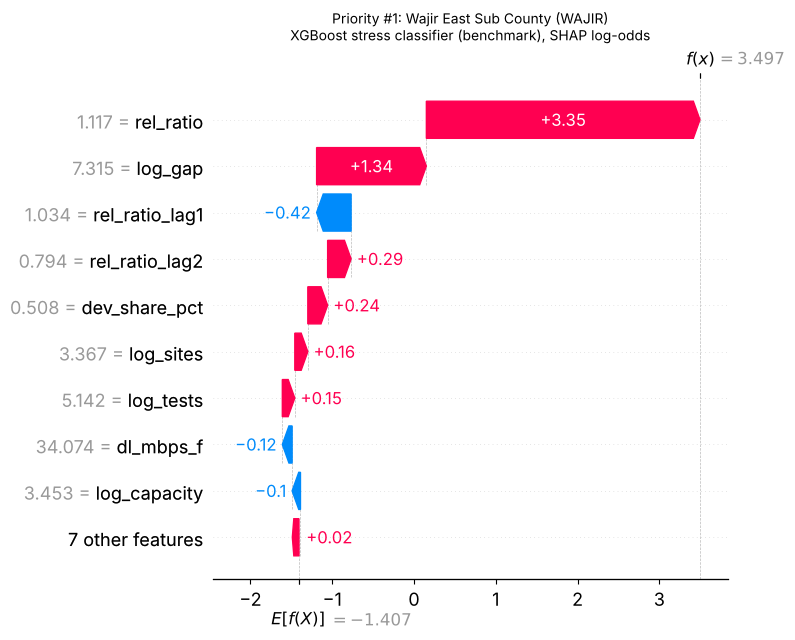

[saved] Outputs/figures/F4.12_local_shap_rank2.png


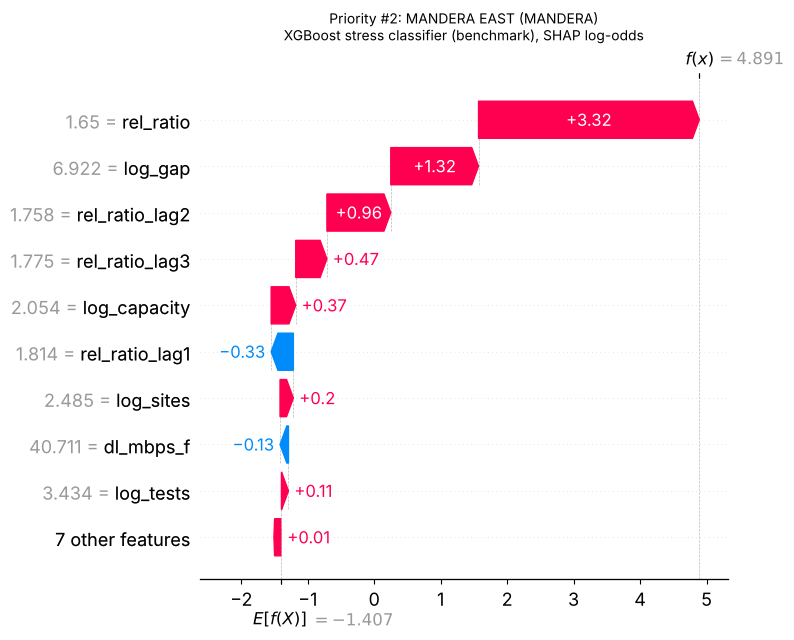

[saved] Outputs/figures/F4.13_local_shap_rank3.png


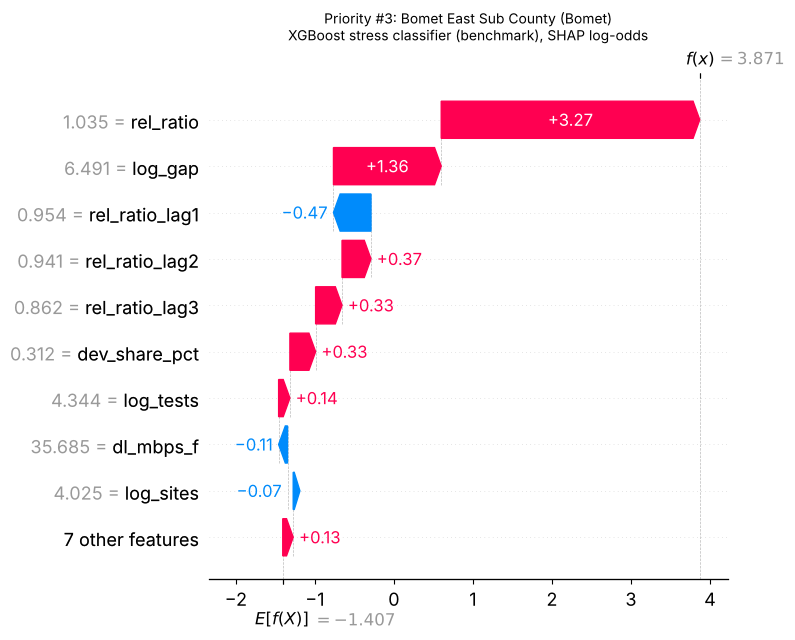

In [9]:
# True where the sub-county has enough Ookla tests AND enough recorded sites (& means "and").
adequate = (forecast['low_confidence'] == 0) & (forecast['sparse_infrastructure'] == 0)
# forecast.index[adequate]: row labels of the adequate sub-counties. np.argsort(-NDS) orders
# them from highest to lowest NDS, and [:3] keeps the top three.
top3 = forecast.index[adequate][np.argsort(-forecast.loc[adequate, 'NDS'].values)[:3]]
for rank, i in enumerate(top3, 1):        # enumerate(..., 1) numbers the items 1, 2, 3
    plt.figure()
    # sv_xgb[i] is the explanation for one sub-county; at most 10 bars, the smallest grouped.
    shap.plots.waterfall(sv_xgb[i], max_display=10, show=False)
    # Title with the sub-county and county names; '\n' starts a second line.
    plt.title(f"Priority #{rank}: {forecast['subcounty'].iloc[i]} ({forecast['county'].iloc[i]})\n"
              "XGBoost stress classifier (benchmark), SHAP log-odds", fontsize=10)
    # Saved as Figures 4.11, 4.12 and 4.13 (10 + rank).
    plt.tight_layout(); save_figure(f'4.{10 + rank}', f'local_shap_rank{rank}'); plt.show()

## Step 6: Maps and County Summary
Sub-county centroids are the mean position of their OpenCellID sites. Marker colour shows the NDS and marker size shows exposure (Ookla devices). Grey dots are all approximate sites, for geographic context.

**How the code works.**
- The loop draws two maps side by side (`ax[0]` and `ax[1]`): the forecast stress probability on the left and the NDS on the right. Each map first plots every site as a tiny grey dot, then the sub-county centroids, coloured by the value and sized by E (`s=10 + 60 * forecast['E']`, so the most exposed sub-counties have the biggest markers). The 8 highest-NDS sub-counties are labelled on the NDS map.
- The county summary (Table 4.27) groups sub-counties by county with `groupby('county').agg(...)`. An entry such as `mean_NDS=('NDS', 'mean')` reads "make a column called `mean_NDS` by taking the mean of `NDS` within each county". `in_top10pct` counts how many of the county's sub-counties are in the overall top 10%.
- Figure 4.15 is a bar chart of the 15 counties with the highest mean NDS.

[saved] Outputs/figures/F4.14_nds_maps.png


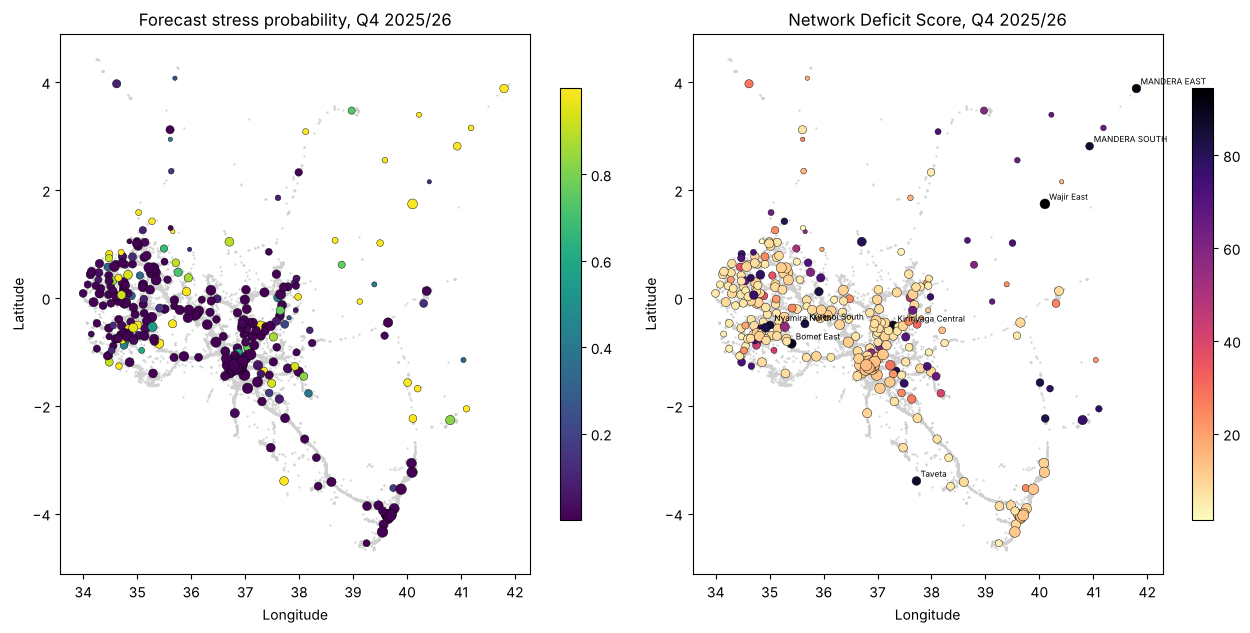

Table 4.27: County summary of the NDS (top 15 shown; all counties saved)
[saved] Outputs/tables/T4.27_county_summary.csv


,subcounties,mean_NDS,max_NDS,in_top10pct,mean_stress_prob
county,,,,,
LAMU,2,77.70,78.86,2,0.91
MANDERA,4,77.65,91.43,2,1.00
WAJIR,4,62.01,94.44,1,0.77
TANA RIVER,3,56.25,82.32,2,0.67
BARINGO,6,51.86,83.05,1,0.60
ISIOLO,3,45.49,69.83,0,0.59
WEST POKOT,4,42.67,80.76,1,0.52
SAMBURU,2,42.35,80.70,1,0.45
Nyamira,5,38.30,85.36,2,0.40


[saved] Outputs/figures/F4.15_county_nds.png


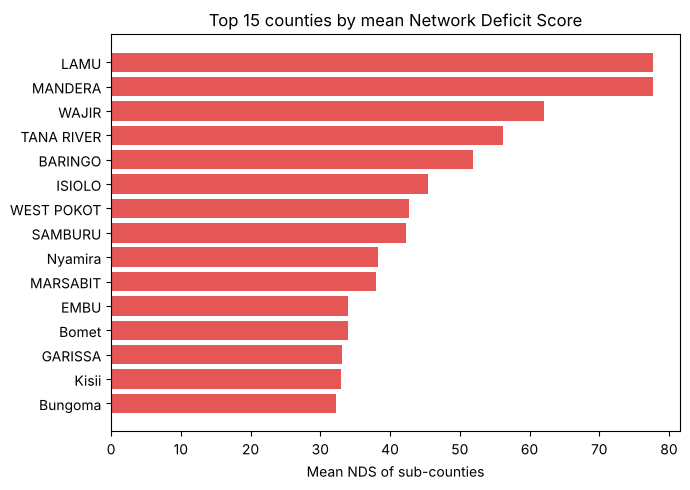

In [10]:
sites = pd.read_csv(PROCESSED + 'sites_all_technologies.csv')    # all sites (Notebook 01)
fig, ax = plt.subplots(1, 2, figsize=(13, 7.5))       # one row of two map panels
# Loop over the two panels; each tuple gives (panel, column to colour by, title, colour map).
for a, col, title, cmap in [(ax[0], 'breach_prob', 'Forecast stress probability, Q4 2025/26', 'viridis'),
                            (ax[1], 'NDS', 'Network Deficit Score, Q4 2025/26', 'magma_r')]:
    a.scatter(sites['lon'], sites['lat'], s=0.3, c='#d0d0d0')      # sites as tiny grey dots
    # Sub-county centroids: colour = value of col, marker size grows with exposure E.
    sc_ = a.scatter(forecast['lon'], forecast['lat'], c=forecast[col], cmap=cmap,
                    s=10 + 60 * forecast['E'], edgecolor='k', linewidth=0.3)
    # Colour scale bar; equal aspect draws a degree of longitude and of latitude the same size.
    plt.colorbar(sc_, ax=a, shrink=0.6); a.set_title(title); a.set_aspect('equal')
    a.set_xlabel('Longitude'); a.set_ylabel('Latitude')
# Label the 8 highest-NDS sub-counties on the NDS map, dropping ' Sub County' to save space;
# xytext=(3, 3) with 'offset points' moves each label slightly up and to the right.
for i in np.argsort(-forecast['NDS'].values)[:8]:
    ax[1].annotate(forecast['subcounty'].iloc[i].replace(' Sub County', ''), (forecast['lon'].iloc[i], forecast['lat'].iloc[i]),
                   fontsize=6, xytext=(3, 3), textcoords='offset points')
plt.tight_layout(); save_figure('4.14', 'nds_maps'); plt.show()

# County summary (Table 4.27) with named aggregation: new_column=(source_column, function).
# 'size' counts the rows; the lambda counts sub-counties whose NDS rank is within the top 10%.
county = (forecast.groupby('county')
          .agg(subcounties=('subcounty', 'size'), mean_NDS=('NDS', 'mean'), max_NDS=('NDS', 'max'),
               in_top10pct=('NDS_rank', lambda r: int((r <= TOPK).sum())), mean_stress_prob=('breach_prob', 'mean'))
          .sort_values('mean_NDS', ascending=False))
print("Table 4.27: County summary of the NDS (top 15 shown; all counties saved)")
save_table(county.round(3), '4.27', 'county_summary', index=True)     # all counties saved
display(county.head(15).round(2))                                      # top 15 shown

# Figure 4.15. iloc[::-1] reverses the row order so the highest county is drawn at the top.
fig, ax = plt.subplots(figsize=(7, 5))
c15 = county.head(15).iloc[::-1]
ax.barh(c15.index, c15['mean_NDS'], color='#e45756'); ax.set_xlabel('Mean NDS of sub-counties')
ax.set_title('Top 15 counties by mean Network Deficit Score')
plt.tight_layout(); save_figure('4.15', 'county_nds'); plt.show()

**How to read this output.**
- **Figure 4.14:** on the left map (viridis colour scale), yellow means a high stress probability and dark purple a low one. On the right map (reversed magma scale), darker markers mean a higher NDS. Big dark markers on the right are sub-counties with both a high score and many exposed users. Areas where dark markers cluster are the pattern that Moran's I measures in Step 4.
- **Table 4.27:** `subcounties` is the number of sub-counties in the county, `mean_NDS` and `max_NDS` are the average and the highest score among them, `in_top10pct` counts its sub-counties in the overall top 10%, and `mean_stress_prob` is the average forecast stress probability (from 0 to 1). A county can have a high `max_NDS` but a modest `mean_NDS` when one sub-county stands out from the rest.
- Counties are ranked by **mean** NDS, so a county with only a few sub-counties can rank high if all of them score high.

## Step 7: Ranked Screening Table (Thesis Table)
Recommended actions are generic screening steps (proposal Section 3.4.6), because final engineering choices need operator data. The infrastructure layer is a **2019 snapshot** in which only about 3% of cells are LTE, so "no LTE" means "no LTE recorded in 2019", not "no LTE today":
- **No LTE in the 2019 layer:** verify current LTE/5G presence; if absent, an LTE / 5G NSA upgrade feasibility study.
- **LTE present:** sector or carrier augmentation and backhaul review.
- **Low data confidence:** verify demand and infrastructure on the ground before acting.

**Data confidence** (proposal Section 3.4.6: high scores with low data confidence are flagged, not presented as definitive priorities):
- *Low (few Ookla tests):* fewer than 20 tests in the last quarter, so the demand share is noisy.
- *Low (sparse infrastructure records):* fewer than 5 OpenCellID sites observed, so the capacity proxy is probably understated.
- *Adequate (2019 infrastructure):* at least 20 tests and 5 recorded sites. The label does not remove the vintage caveat above.

The thesis table therefore has two parts: the **priority list** (adequate data, ranked) and a **watch list** (in the overall top 10% but low confidence). Each row shows the three NDS components, the two features that move the GRU-MTL stress probability the most (signed SHAP values on the probability scale), and the strongest **independent** predictor, because the top feature is almost always the sub-county's own current stress ratio, usually followed by its current gap or the capacity proxy (all target-formula components, Table 4.23). The gap is left blank where the stress probability is below 5%, for the reason given in Step 3.

Coordinates are rounded to 2 decimals (≈ 1 km), in line with the proposal's ethics section.

**How the code works.**
- `confidence(r)` gives each row a data-confidence label from the flags made in Notebook 04 (`sparse_infrastructure` is checked first, then `low_confidence`); `.apply(confidence, axis=1)` runs it on every row.
- `action(n_lte, conf)` chooses the screening action from the number of LTE cells recorded in 2019, and puts "verify on the ground first" in front of it for low-confidence rows.
- `top_features(i, k)` takes sub-county `i`'s seed-averaged GRU-MTL SHAP values (`sv_gru_mean`), sorts them by absolute size and writes the `k` largest as text with their sign, for example "current stress ratio (+0.25)" (an illustrative number). With `independent_only=True` it looks only at the independent predictors.
- `blue` is the forecast table sorted from highest to lowest NDS, with the new text columns added; `thesis` keeps and renames the columns needed for the report.
- `priority` keeps the adequate-data rows and numbers them 1, 2, 3, ... (`Priority rank`); `watch` keeps the low-confidence rows that are in the overall top 10%.

In [11]:
ADEQUATE = 'Adequate (2019 infrastructure)'
# Data-confidence label for one row r of the table (r['column'] reads one value of the row).
def confidence(r):
    if r['sparse_infrastructure'] == 1:
        return 'Low (sparse infrastructure records)'
    # Conditional expression: value_if_true if condition else value_if_false.
    return 'Low (few Ookla tests)' if r['low_confidence'] == 1 else ADEQUATE

# Screening action from the number of LTE cells recorded in 2019 and the confidence label.
def action(n_lte, conf):
    if n_lte == 0:
        a = 'Verify current LTE/5G presence (none in the 2019 registry); if absent, LTE / 5G NSA upgrade feasibility study'
    else:
        a = 'Sector/carrier augmentation and backhaul review'
    # Low-confidence rows get a "verify first" instruction in front of the action.
    return a if conf == ADEQUATE else 'Verify demand and infrastructure on the ground first. ' + a

# The k features with the largest |SHAP| for sub-county i, written as text with signed values.
def top_features(i, k=2, independent_only=False):
    v = sv_gru_mean.iloc[i]      # signed seed-average SHAP values of row i, one per feature
    if independent_only:
        v = v[[c for c in v.index if c not in TARGET_COMPONENT]]    # independent ones only
    top = v.abs().sort_values(ascending=False).index[:k]    # names of the k largest |SHAP|
    # LABEL.get(c, c) uses the readable label if there is one, otherwise the code name.
    # {v[c]:+.2f} always shows the sign and 2 decimals, e.g. +0.31 or -0.05.
    return ', '.join(f"{LABEL.get(c, c)} ({v[c]:+.2f})" for c in top)

# Copy of the forecast table sorted from highest to lowest NDS (.copy() leaves forecast alone).
blue = forecast.sort_values('NDS', ascending=False).copy()
blue['Data confidence'] = blue.apply(confidence, axis=1)       # axis=1: apply row by row
blue['Recommended screening action'] = [action(n, c) for n, c in zip(blue['n_LTE'], blue['Data confidence'])]
# Text such as "3–7": the best and worst rank across the 5 seeds (astype(str) turns numbers
# into text so they can be joined with '+').
blue['Rank range across seeds'] = blue['rank_min_seeds'].astype(str) + '–' + blue['rank_max_seeds'].astype(str)
blue['NDS parts B / G / E'] = [f"{b:.2f} / {g:.2f} / {e:.2f}" for b, g, e in zip(blue['B'], blue['G'], blue['E'])]
# The row labels of blue are the original row positions in forecast (0, 1, 2, ...), which
# are also the row positions in sv_gru_mean, so top_features finds the right sub-county.
blue['Top GRU-MTL SHAP features'] = [top_features(i) for i in blue.index]
blue['Top independent predictor (SHAP)'] = [top_features(i, 1, independent_only=True) for i in blue.index]
# Keep only the report columns, in report order.
thesis = blue[['NDS_rank', 'county', 'subcounty', 'lat', 'lon', 'NDS', 'NDS parts B / G / E', 'breach_prob', 'pred_gap_TB',
               'devices_last2q', 'n_sites', 'n_LTE', 'Rank range across seeds', 'Top GRU-MTL SHAP features', 'Top independent predictor (SHAP)',
               'Data confidence', 'Recommended screening action']].copy()
thesis['lat'], thesis['lon'] = thesis['lat'].round(2), thesis['lon'].round(2)    # about 1 km
thesis.loc[thesis['breach_prob'] < P_FLOOR, 'pred_gap_TB'] = np.nan     # gap head extrapolates for unlikely stress
thesis['breach_prob'] = (100 * thesis['breach_prob'].astype(float)).round(1)     # as a %
# Readable column names for the report.
thesis = thesis.rename(columns={'NDS_rank': 'NDS rank (all)', 'breach_prob': 'Stress prob. (%)',
                                'pred_gap_TB': 'Gap if stressed (TB, downscaled estimate)',
                                'devices_last2q': 'Ookla devices (2q mean)', 'n_sites': 'Sites (2019)', 'n_LTE': 'LTE cells (2019)'})
thesis['NDS'] = thesis['NDS'].round(1)
thesis['Gap if stressed (TB, downscaled estimate)'] = thesis['Gap if stressed (TB, downscaled estimate)'].round(1)

# Priority list: adequate-data rows only (already in NDS order), numbered from 1.
priority = thesis[thesis['Data confidence'] == ADEQUATE].copy()
priority.insert(0, 'Priority rank', np.arange(1, len(priority) + 1))
# Watch list: low-confidence rows (!= means "not equal to") that are in the overall top 10%.
watch = thesis[(thesis['Data confidence'] != ADEQUATE) & (thesis['NDS rank (all)'] <= TOPK)]
save_table(priority, '4.28', 'priority_list')
save_table(watch, '4.29', 'watch_list')
print(f"Adequate-data sub-counties: {len(priority)} of {N}. Low-confidence sub-counties in the overall top 10%: {len(watch)} of {TOPK}")
print("Table 4.28: Priority list, adequate-data sub-counties (top 20 shown; all saved)")
display(priority.head(20))
print("Table 4.29: Watch list, low-confidence sub-counties in the overall top 10%")
display(watch)

[saved] Outputs/tables/T4.28_priority_list.csv
[saved] Outputs/tables/T4.29_watch_list.csv
Adequate-data sub-counties: 176 of 294. Low-confidence sub-counties in the overall top 10%: 17 of 30
Table 4.28: Priority list, adequate-data sub-counties (top 20 shown; all saved)


,Priority rank,NDS rank (all),county,subcounty,lat,lon,NDS,NDS parts B / G / E,Stress prob. (%),"Gap if stressed (TB, downscaled estimate)",Ookla devices (2q mean),Sites (2019),LTE cells (2019),Rank range across seeds,Top GRU-MTL SHAP features,Top independent predictor (SHAP),Data confidence,Recommended screening action
285,1,1,WAJIR,Wajir East Sub County,1.74,40.10,94.4,0.99 / 1.00 / 0.67,98.8,589.3,56.0,28,0,1–1,"current stress ratio (+0.43), current gap (+0.25)",neighbours' stress ratio (+0.05),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
154,2,2,MANDERA,MANDERA EAST,3.88,41.80,91.4,1.00 / 0.98 / 0.47,99.8,548.7,16.5,11,0,2–4,"current stress ratio (+0.65), current gap (+0.17)",recorded sites (+0.04),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
14,3,3,Bomet,Bomet East Sub County,-0.85,35.41,89.8,0.99 / 0.91 / 0.56,99.0,403.4,28.0,55,0,2–3,"current stress ratio (+0.53), current gap (+0.25)",Ookla tests (+0.02),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
112,4,4,KIRINYAGA,Kirinyaga Central Sub County,-0.52,37.29,88.7,0.98 / 0.88 / 0.62,97.5,345.9,41.0,53,0,3–4,"current stress ratio (+0.52), current gap (+0.29)",Ookla tests (-0.03),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
220,5,7,Nyamira,Nyamira North Sub County,-0.50,35.01,85.4,1.00 / 0.85 / 0.39,99.8,302.4,9.5,9,0,6–7,"current stress ratio (+0.50), current gap (+0.15)",Ookla tests (+0.06),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
184,6,9,BARINGO,Mogotio Sub County,0.12,35.91,83.1,0.99 / 0.77 / 0.46,98.7,214.4,15.0,44,0,9–12,"current stress ratio (+0.48), current gap (+0.19)",Ookla tests (+0.03),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
221,7,10,Nyamira,Nyamira Sub County,-0.55,34.92,82.8,0.96 / 0.76 / 0.53,96.3,210.5,23.5,18,0,9–13,"current stress ratio (+0.38), current gap (+0.21)",recorded sites (+0.05),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
245,8,15,SAMBURU,Samburu Central Sub County,1.04,36.71,80.7,0.90 / 0.80 / 0.52,89.6,249.2,22.5,27,0,9–18,"current stress ratio (+0.47), current gap (+0.28)",download speed (-0.06),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
162,9,18,Kakamega,Malava Sub County,0.43,34.83,78.3,0.93 / 0.69 / 0.51,93.4,151.1,20.5,54,0,14–20,"current gap (+0.28), current stress ratio (+0.27)",Ookla tests (+0.04),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...
182,10,21,MAKUENI,Mbooni Sub County,-1.58,37.49,77.5,0.94 / 0.69 / 0.40,94.4,154.4,10.5,35,0,16–22,"current stress ratio (+0.34), current gap (+0.18)",Ookla tests (+0.09),Adequate (2019 infrastructure),Verify current LTE/5G presence (none in the 20...


Table 4.29: Watch list, low-confidence sub-counties in the overall top 10%


,NDS rank (all),county,subcounty,lat,lon,NDS,NDS parts B / G / E,Stress prob. (%),"Gap if stressed (TB, downscaled estimate)",Ookla devices (2q mean),Sites (2019),LTE cells (2019),Rank range across seeds,Top GRU-MTL SHAP features,Top independent predictor (SHAP),Data confidence,Recommended screening action
261,5,TAITA TAVETA,Taveta Sub County,-3.39,37.72,86.6,1.00 / 0.84 / 0.49,99.7,295.9,18.5,21,0,5–6,"current stress ratio (+0.64), current gap (+0.20)",recorded sites (+0.03),Low (few Ookla tests),Verify demand and infrastructure on the ground...
155,6,MANDERA,MANDERA SOUTH,2.81,40.93,86.0,1.00 / 0.87 / 0.36,99.9,339.0,8.0,2,0,5–7,"current stress ratio (+0.51), current gap (+0.08)",recorded sites (+0.04),Low (sparse infrastructure records),Verify demand and infrastructure on the ground...
131,8,Nakuru,Kuresoi South Sub County,-0.48,35.65,84.2,1.00 / 0.81 / 0.40,99.5,258.5,10.5,9,0,8–8,"current stress ratio (+0.52), current gap (+0.17)",recorded sites (+0.05),Low (few Ookla tests),Verify demand and infrastructure on the ground...
43,11,TANA RIVER,Galole Sub County,-1.57,40.01,82.3,1.00 / 0.77 / 0.36,99.5,221.8,8.0,15,0,9–12,"current stress ratio (+0.70), current gap (+0.18)",recorded sites (+0.04),Low (few Ookla tests),Verify demand and infrastructure on the ground...
82,12,Machakos,Kangundo Sub County,-1.35,37.35,82.3,1.00 / 0.79 / 0.32,99.8,233.2,6.0,12,0,10–13,"current stress ratio (+0.53), current gap (+0.13)",Ookla tests (+0.06),Low (few Ookla tests),Verify demand and infrastructure on the ground...
47,13,TANA RIVER,Garsen Sub County,-2.24,40.11,81.0,0.99 / 0.74 / 0.36,99.0,194.7,8.0,14,0,13–15,"current stress ratio (+0.52), current gap (+0.17)",recorded sites (+0.04),Low (few Ookla tests),Verify demand and infrastructure on the ground...
232,14,WEST POKOT,Pokot South Sub County,1.42,35.27,80.8,1.00 / 0.78 / 0.23,100.0,227.8,3.0,3,0,13–16,"current stress ratio (+0.63), current gap (+0.07)",recorded sites (+0.03),Low (sparse infrastructure records),Verify demand and infrastructure on the ground...
214,16,Kakamega,Navakholo Sub County,0.37,34.65,79.7,1.00 / 0.74 / 0.27,99.8,188.6,4.0,16,0,15–17,"current stress ratio (+0.59), current gap (+0.13)",recorded sites (+0.03),Low (few Ookla tests),Verify demand and infrastructure on the ground...
137,17,LAMU,LAMU EAST,-2.06,41.10,78.9,1.00 / 0.74 / 0.21,100.0,187.9,2.5,3,0,17–19,"current stress ratio (+0.60), current gap (+0.10)",Ookla tests (+0.08),Low (sparse infrastructure records),Verify demand and infrastructure on the ground...
61,19,GARISSA,Ijara Sub County,-1.68,40.20,78.0,1.00 / 0.70 / 0.23,99.9,161.3,3.0,3,0,18–21,"current stress ratio (+0.67), current gap (+0.09)",recorded sites (+0.05),Low (sparse infrastructure records),Verify demand and infrastructure on the ground...


**How to read the priority list (Table 4.28) and the watch list (Table 4.29).**
- **Priority rank** is the position among the adequate-data sub-counties only, while **NDS rank (all)** is the position among all sub-counties. Where the overall ranks skip numbers, the missing sub-counties have low data confidence: those within the overall top 10% appear on the watch list, and the rest appear only in the full ranking (Table 4.32).
- **NDS parts B / G / E** shows the three components behind the score, so you can see *why* a sub-county scores high. For example (illustration), "0.95 / 0.80 / 0.40" means a very likely stress forecast with a large gap but moderate exposure.
- **Stress prob. (%)** is the GRU-MTL seed-average probability as a percentage, and **Gap if stressed** is the predicted shortfall in terabytes if stress occurs (blank where the probability is below 5%).
- **Rank range across seeds** shows the best and worst rank the sub-county gets when the NDS is computed from each of the 5 GRU-MTL seeds separately. A narrow range (for example, an illustrative "3–5") means the position does not depend on which seed is used; a wide range means the position is less certain.
- **Top GRU-MTL SHAP features** lists the two features that moved this sub-county's stress probability the most, with their signed SHAP values on the probability scale. A value of +0.20 (illustration) means that feature raised the probability by about 20 percentage points compared with the model's average on the background sample; a negative value means it lowered the probability. **Top independent predictor** gives the strongest feature that is not part of the target formula.
- **Watch list:** these sub-counties are in the overall top 10%, but their data are weak (few Ookla tests or few recorded sites). They are not discarded, because they may well need attention, but the first step for them is to verify demand and infrastructure on the ground before treating them as priorities.

## Step 8: Candidate Sites Inside the Top-Priority Sub-Counties
The forecasts are made for sub-counties, but upgrades happen at physical sites. For each of the 10 highest-ranked sub-counties on the priority list, the **three approximate sites whose catchments hold the most Ookla test devices** (a crowdsourced demand proxy; mean of the last two quarters; ties broken by number of cells) are listed. There is no filter on technology: each site's screening action is set by its highest recorded technology, as in Step 7. This narrows the screening from a sub-county to specific sites, as proposal Section 3.4.6 intended ("a ranked table of approximate coordinates").

These are **not** site-level forecasts. They are the sites that carry most of the sub-county's observed Ookla devices, and therefore the first places to check. Coordinates are rounded to 2 decimals (about 1 km).

**How the code works.**
- `site_dem` holds the Ookla devices assigned to each site's catchment (the area served by that site, from Notebook 03) in each quarter. `dev2` adds up each site's devices over the last two quarters and divides by 2, giving a two-quarter average.
- `sites_c` is the site table with this average attached (sites with no devices get 0). `sc_share_%` is each site's share of its sub-county's devices; `groupby('subcounty')[...].transform('sum')` gives every site row the total of its sub-county.
- The loop takes the top 10 rows of `priority`, finds the sites in each of those sub-counties, sorts them by devices (then by number of cells) and keeps the first three.

**How to read Table 4.30.** There are three rows per priority sub-county. *Candidate* 1 is the site whose catchment holds the most Ookla devices. *Highest technology (2019)* and *Cells (GSM/UMTS/LTE)* describe the recorded equipment, and *Share of sub-county devices (%)* shows how much of the sub-county's observed demand that one site carries: a high share means that checking this single site covers much of the problem.

In [12]:
# Ookla devices in each site's catchment, per quarter (Notebook 03).
site_dem = pd.read_parquet(PROCESSED + 'site_catchment_demand.parquet')
last_q = int(site_dem['q_idx'].max())        # index of the last observed quarter
# Keep the last two quarters, add up the devices per site and divide by 2 (two-quarter mean).
dev2 = site_dem[site_dem.q_idx >= last_q - 1].groupby('site_id')['devices'].sum() / 2
# Site table indexed by site_id. assign(...) adds the column devices_last2q: reindex lines dev2
# up with the site order, and fillna(0) gives 0 to sites without recorded devices.
sites_c = sites.set_index('site_id').assign(devices_last2q=lambda d: dev2.reindex(d.index).fillna(0))
# Each site's share of its sub-county's devices. transform('sum') puts the sub-county total on
# every site row; replace(0, np.nan) avoids dividing by zero.
sites_c['sc_share_%'] = 100 * sites_c['devices_last2q'] / sites_c.groupby('subcounty')['devices_last2q'].transform('sum').replace(0, np.nan)

rows = []      # one dictionary per candidate site, turned into a table at the end
# iterrows() goes through the 10 top priority rows as (index, row) pairs; '_' is a throwaway
# name for the index, which is not needed.
for _, r in priority.head(10).iterrows():
    # Sites in this sub-county, sorted by devices and then cells (largest first); keep 3.
    cands = sites_c[sites_c['subcounty'] == r['subcounty']].sort_values(['devices_last2q', 'n_cells'], ascending=False).head(3)
    for k, (sid, c) in enumerate(cands.iterrows(), 1):     # k = 1, 2, 3; c is one site's row
        # Coordinates rounded to about 1 km; the action depends on whether the site had LTE
        # cells in 2019.
        rows.append({'Priority rank': r['Priority rank'], 'Sub-county': r['subcounty'], 'County': r['county'],
                     'Candidate': k, 'Lat': round(c['lat'], 2), 'Lon': round(c['lon'], 2),
                     'Highest technology (2019)': c['tech'], 'Cells (GSM/UMTS/LTE)': f"{c['n_GSM']}/{c['n_UMTS']}/{c['n_LTE']}",
                     'Ookla devices in catchment (2q mean)': round(c['devices_last2q'], 1),
                     'Share of sub-county devices (%)': round(c['sc_share_%'], 1),
                     'Screening action': action(c['n_LTE'], ADEQUATE)})
cand_sites = pd.DataFrame(rows)      # list of dictionaries -> table (Table 4.30)
print("Table 4.30: Candidate approximate sites in the 10 highest-priority sub-counties")
display(save_table(cand_sites, '4.30', 'candidate_sites'))

Table 4.30: Candidate approximate sites in the 10 highest-priority sub-counties
[saved] Outputs/tables/T4.30_candidate_sites.csv


,Priority rank,Sub-county,County,Candidate,Lat,Lon,Highest technology (2019),Cells (GSM/UMTS/LTE),Ookla devices in catchment (2q mean),Share of sub-county devices (%),Screening action
0,1,Wajir East Sub County,WAJIR,1,1.76,40.04,GSM only,1/0/0,15.5,27.7,Verify current LTE/5G presence (none in the 20...
1,1,Wajir East Sub County,WAJIR,2,1.75,40.05,UMTS (no LTE),0/2/0,8.0,14.3,Verify current LTE/5G presence (none in the 20...
2,1,Wajir East Sub County,WAJIR,3,1.75,40.06,UMTS (no LTE),0/1/0,7.5,13.4,Verify current LTE/5G presence (none in the 20...
3,2,MANDERA EAST,MANDERA,1,3.94,41.86,UMTS (no LTE),0/2/0,6.0,36.4,Verify current LTE/5G presence (none in the 20...
4,2,MANDERA EAST,MANDERA,2,3.96,41.89,GSM only,1/0/0,2.5,15.2,Verify current LTE/5G presence (none in the 20...
5,2,MANDERA EAST,MANDERA,3,3.92,41.83,UMTS (no LTE),0/2/0,2.0,12.1,Verify current LTE/5G presence (none in the 20...
6,3,Bomet East Sub County,Bomet,1,-0.94,35.42,GSM only,1/0/0,4.5,16.1,Verify current LTE/5G presence (none in the 20...
7,3,Bomet East Sub County,Bomet,2,-0.78,35.34,GSM only,2/0/0,3.0,10.7,Verify current LTE/5G presence (none in the 20...
8,3,Bomet East Sub County,Bomet,3,-0.86,35.39,UMTS (no LTE),0/1/0,3.0,10.7,Verify current LTE/5G presence (none in the 20...
9,4,Kirinyaga Central Sub County,KIRINYAGA,1,-0.56,37.32,GSM only,1/0/0,6.5,15.9,Verify current LTE/5G presence (none in the 20...


## Step 9: Summary of the Research Hypotheses
The verdicts below are computed from the saved tables, so they always match the latest run. The rules are fixed in advance:
- **H1** uses Table 4.18 (GRU-MTL against the single-task GRUs and against XGBoost). Discrimination is the hypothesis as stated, so a comparison counts only if the ROC-AUC difference is positive, the DeLong p-value is below 0.05 **and** the sub-county cluster-bootstrap CI excludes 0. Supported if both comparisons count, partly supported if one does. Gap errors are shown as supporting evidence only.
- **H2** uses two rows of Table 4.18: GRU-MTL with versus without spatial-lag features, and T-GCN versus GRU-MTL without spatial lags (graph convolution alone). A mechanism counts if it significantly improves discrimination (same rule as H1) or the gap error (Diebold–Mariano p < 0.05). Supported if both count, partly supported if one does.
- **H3** uses Table 4.19, for both tasks. Supported if neither the stress nor the gap residuals are significantly autocorrelated (p < 0.05) in any test quarter, partly supported if one task is free of autocorrelation.
- **H4** uses Table 4.26 (Dirichlet counted once, by its 5th percentile). Supported if the top-10% overlap is at least 0.70 in every variant, partly supported if it is in at least half.

The tests named here come from Notebook 04: the **DeLong test** checks whether two models' ROC-AUC values differ significantly, and the **Diebold–Mariano (DM) test** checks whether two models' forecast errors differ significantly.

**How the code works.**
- Tables 4.18 and 4.19 are read back from `Outputs/tables/` (`encoding='utf-8-sig'` matches the way `save_table` wrote them).
- `vs(key, label)` looks up one comparison row of Table 4.18 and returns three things: whether it passes the discrimination rule (`disc`), whether it passes the gap-error rule (`gap`), and a text summary of the evidence. In the code, `and` requires every condition to hold, while `or` requires at least one.
- `grade(n_ok, n_all)` turns a count of passed checks into a verdict: all passed gives Supported, some gives Partly supported, none gives Not supported. Since `int(True)` is 1 and `int(False)` is 0, adding them up counts the passes.
- H3 requires every test quarter's Moran's I p-value to be at least 0.05 (`.all()`), checked separately for the stress and gap residuals.
- H4 reuses the `counted` rows of Table 4.26 from Step 4.

**How to read Table 4.31.** There is one row per hypothesis: the statement tested, the evidence behind the verdict (differences, p-values and confidence intervals) and the verdict itself. In the evidence text, a **positive** ΔROC-AUC favours the first model named, and a **negative** ΔMAE means the first model has smaller gap errors. A confidence interval that contains 0, or a p-value of 0.05 or more, means the difference is not statistically significant.

In [13]:
# Read Table 4.18 (model comparison tests) and Table 4.19 (residual Moran's I), Notebook 04.
# set_index('Comparison') lets a row be looked up by its comparison name with .loc[...].
tests = pd.read_csv(TABLES + 'T4.18_hypothesis_tests.csv', encoding='utf-8-sig').set_index('Comparison')
moran_res = pd.read_csv(TABLES + 'T4.19_residual_moran.csv', encoding='utf-8-sig')
REF = 'GRU-MTL (proposed)'       # name of the proposed model in Table 4.18

def vs(key, label):
    r = tests.loc[key]           # the row for this comparison
    # Discrimination counts only if the ROC-AUC gain is positive, DeLong p < 0.05 AND the lower
    # end of the cluster-bootstrap CI is above 0 (so the interval excludes 0).
    disc = (r['ΔROC-AUC'] > 0) and (r['DeLong p'] < 0.05) and (r['ΔROC CI low'] > 0)
    # The gap error counts if the first model's MAE is lower (negative Δ) and DM p < 0.05.
    gap = (r['ΔMAE expected gap (TB)'] < 0) and (r['DM p'] < 0.05)
    # Evidence text; :+.4f shows the sign and 4 decimals, :.3f shows 3 decimals.
    text = (f"{label}: ΔROC-AUC {r['ΔROC-AUC']:+.4f} (DeLong p = {r['DeLong p']:.3f}; cluster CI [{r['ΔROC CI low']:+.4f}, {r['ΔROC CI high']:+.4f}]; "
            f"ΔPR-AUC CI [{r['ΔPR-AUC CI low']:+.4f}, {r['ΔPR-AUC CI high']:+.4f}]); "
            f"ΔMAE expected gap {r['ΔMAE expected gap (TB)']:+.2f} TB (DM p = {r['DM p']:.3f})")
    return disc, gap, text

# Verdict from the number of checks passed (n_ok) out of the number required (n_all).
def grade(n_ok, n_all):
    return 'Supported' if n_ok == n_all else ('Partly supported' if n_ok > 0 else 'Not supported')

# H1: GRU-MTL against the single-task GRUs and against XGBoost (discrimination only).
d_st, g_st, t_st = vs(f'{REF} vs Single-task GRUs (stress + gap)', 'GRU-MTL vs single-task GRUs')
d_xg, g_xg, t_xg = vs(f'{REF} vs XGBoost (two-part)', 'GRU-MTL vs XGBoost')
h1 = grade(int(d_st) + int(d_xg), 2)      # int(True) = 1, so this counts the passes

# H2: each spatial mechanism counts if it improves discrimination OR the gap error.
d_sp, g_sp, t_sp = vs(f'{REF} vs GRU-MTL without spatial lags', 'Spatial lags (GRU-MTL vs no-lag GRU-MTL)')
d_gc, g_gc, t_gc = vs('T-GCN (graph conv + GRU) vs GRU-MTL without spatial lags', 'Graph convolution (T-GCN vs no-lag GRU-MTL)')
h2 = grade(int(d_sp or g_sp) + int(d_gc or g_gc), 2)

# H3: True only if every test quarter's permutation p-value is >= 0.05 (no significant
# autocorrelation), checked separately for the stress and the gap residuals.
stress_free = (moran_res['p stress (perm.)'] >= 0.05).all()
gap_free = (moran_res['p gap (perm.)'] >= 0.05).all()
h3 = grade(int(stress_free) + int(gap_free), 2)
# Evidence text: Moran's I and p for each test quarter, for both kinds of residual.
t_h3 = ('Stress residuals: ' + '; '.join(f"{q}: I = {i:+.3f} (p = {p:.3f})" for q, i, p in
        zip(moran_res['Quarter'], moran_res["Moran's I (stress residual)"], moran_res['p stress (perm.)'])) +
        ' | Gap residuals: ' + '; '.join(f"{q}: I = {i:+.3f} (p = {p:.3f})" for q, i, p in
        zip(moran_res['Quarter'], moran_res["Moran's I (gap residual)"], moran_res['p gap (perm.)'])))

# H4: top-10% overlap >= 0.70 in the counted variants (Dirichlet counted once).
ok = counted['Top-10% overlap'] >= 0.70
# Supported if all pass, partly supported if at least half pass (ok.mean() = share passing).
h4 = 'Supported' if ok.all() else ('Partly supported' if ok.mean() >= 0.5 else 'Not supported')
lo_rho = counted.loc[counted['Spearman ρ'].idxmin()]     # variant with the lowest Spearman ρ
# Evidence text; failing variants are listed only if there are any.
t_h4 = (f"Overlap ≥ 0.70 in {ok.sum()} of {len(ok)} variants"
        + ("" if ok.all() else "; fails for: " + ", ".join(f"{v} ({o:.3f})" for v, o in
                                                        zip(counted.loc[~ok, 'Variant'], counted.loc[~ok, 'Top-10% overlap'])))
        + f"; lowest Spearman ρ {lo_rho['Spearman ρ']:.3f} ({lo_rho['Variant']}); "
          f"lowest county ρ {counted['County ρ (mean NDS)'].min():.3f}")

# Table 4.31: one row per hypothesis.
t431 = pd.DataFrame([
    {'Hypothesis': 'H1', 'Statement': 'GRU-MTL discriminates stress better than single-task GRUs and XGBoost',
     'Evidence': t_st + ' | ' + t_xg, 'Verdict': h1},
    {'Hypothesis': 'H2', 'Statement': 'Spatial information (spatial lags or graph convolution) improves forecasts',
     'Evidence': t_sp + ' | ' + t_gc, 'Verdict': h2},
    {'Hypothesis': 'H3', 'Statement': 'GRU-MTL residuals show no significant spatial autocorrelation',
     'Evidence': t_h3, 'Verdict': h3},
    {'Hypothesis': 'H4', 'Statement': 'The NDS top 10% is robust (overlap ≥ 0.70) to weights and model choice',
     'Evidence': t_h4, 'Verdict': h4},
])
print("Table 4.31: Summary of the research hypotheses")
# Show the full evidence text in each cell instead of cutting it off with '...'.
pd.set_option('display.max_colwidth', None)
display(save_table(t431, '4.31', 'hypothesis_summary'))

Table 4.31: Summary of the research hypotheses
[saved] Outputs/tables/T4.31_hypothesis_summary.csv


,Hypothesis,Statement,Evidence,Verdict
0,H1,GRU-MTL discriminates stress better than single-task GRUs and XGBoost,"GRU-MTL vs single-task GRUs: ΔROC-AUC +0.0000 (DeLong p = 0.900; cluster CI [-0.0006, +0.0007]; ΔPR-AUC CI [-0.0027, +0.0022]); ΔMAE expected gap +0.09 TB (DM p = 0.768) | GRU-MTL vs XGBoost: ΔROC-AUC +0.0017 (DeLong p = 0.206; cluster CI [-0.0009, +0.0051]; ΔPR-AUC CI [-0.0064, +0.0105]); ΔMAE expected gap +0.87 TB (DM p = 0.289)",Not supported
1,H2,Spatial information (spatial lags or graph convolution) improves forecasts,"Spatial lags (GRU-MTL vs no-lag GRU-MTL): ΔROC-AUC +0.0002 (DeLong p = 0.742; cluster CI [-0.0010, +0.0018]; ΔPR-AUC CI [-0.0054, +0.0010]); ΔMAE expected gap +0.41 TB (DM p = 0.217) | Graph convolution (T-GCN vs no-lag GRU-MTL): ΔROC-AUC -0.0015 (DeLong p = 0.033; cluster CI [-0.0031, -0.0001]; ΔPR-AUC CI [-0.0096, -0.0003]); ΔMAE expected gap +0.09 TB (DM p = 0.683)",Not supported
2,H3,GRU-MTL residuals show no significant spatial autocorrelation,Stress residuals: Q4_24_25: I = -0.057 (p = 0.084); Q1_25_26: I = +0.036 (p = 0.233); Q2_25_26: I = -0.008 (p = 0.847); Q3_25_26: I = +0.008 (p = 0.751) | Gap residuals: Q4_24_25: I = +0.011 (p = 0.452); Q1_25_26: I = +0.120 (p = 0.001); Q2_25_26: I = +0.023 (p = 0.295); Q3_25_26: I = +0.001 (p = 0.866),Partly supported
3,H4,The NDS top 10% is robust (overlap ≥ 0.70) to weights and model choice,Overlap ≥ 0.70 in 7 of 7 variants; lowest Spearman ρ 0.474 (Likelihood only (B)); lowest county ρ 0.737,Supported


## Step 10: Full Ranking (Appendix)
The complete ranked table for all sub-counties, with the same columns as the watch list, is saved as Table 4.32 for the appendix. It is saved but not displayed because it is too long to read comfortably in the notebook; open the CSV file in `Outputs/tables/` (for example in Excel) to browse it.

In [14]:
print(f"Table 4.32: Full NDS ranking, all {len(thesis)} sub-counties (suggested for the appendix)")
# Assigning the result to '_' (a throwaway name) stops Jupyter from displaying the whole table.
_ = save_table(thesis, '4.32', 'full_nds_ranking')

Table 4.32: Full NDS ranking, all 294 sub-counties (suggested for the appendix)
[saved] Outputs/tables/T4.32_full_nds_ranking.csv


### Summary of Notebook 05 (and of the pipeline)
The main findings, with the table to cite for each:
- **Drivers (Tables 4.23–4.24):** 76.5% of GRU-MTL's |SHAP| (89.1% for XGBoost) goes to target-formula components, mainly the current stress ratio and gap, then the capacity proxy. That is persistence by construction, not an independent cause. Among independent predictors, Ookla test volume (8.3%), recorded sites (6.2%), the spatial neighbourhood (4.1%) and observed speed (3.2%) carry most of the remaining 23.5%. The rankings are stable across seeds (mean Spearman 0.91) and XGBoost training windows (0.96), and agree moderately between model families (0.62).
- **NDS (Tables 4.25–4.27):** B and G are strongly related (Spearman 0.80) and both are negatively related to E: stressed sub-counties tend to have fewer Ookla devices. The ranking follows G most closely (Spearman 0.81), then B (0.47). E is almost uncorrelated with the overall score (0.05) but not negligible: G is 0 for the 204 of 294 sub-counties with a stress probability below 5%, and E orders them, so dropping E (0.6/0.4/0, Table 4.26) lowers the Spearman with the base ranking to 0.48 while the top 10% barely moves (overlap 0.90). The NDS is spatially clustered (Moran's I = 0.22, p = 0.001): highest in the north-east and on the northern coast (Lamu, Mandera, Wajir, Tana River), then in the northern Rift Valley and the north (Baringo, Isiolo, West Pokot, Samburu, Marsabit) and in parts of the western highlands (Nyamira, Bomet, Kisii) (Table 4.27).
- **H4 (Table 4.26):** the overall top 10% (30 sub-counties) overlaps by at least 0.70 in all 7 variants, so H4 is supported. The weakest case is "likelihood only", exactly at the threshold (21 of 30; Spearman 0.47). The exposure-led weights move counties the most (county ρ = 0.74).
- **Screening (Tables 4.28–4.30):** 176 of 294 sub-counties have adequate data. The priority list is led by Wajir East, Mandera East, Bomet East, Kirinyaga Central and Nyamira North. 17 of the overall top 30 go to the watch list (10 for few Ookla tests, 7 for sparse infrastructure records). None of the top 10 priority sub-counties had LTE recorded in 2019, so the first step everywhere is to verify current LTE/5G presence.
- **Hypotheses (Table 4.31):** H1 not supported, H2 not supported, H3 partly supported, H4 supported.
- All tables are in `Outputs/tables/` (Tables 4.1–4.32) and all figures in `Outputs/figures/` (Figures 4.1–4.15), numbered in the order they appear across Notebooks 01–05.